<div style="border-left: 5px solid #4285f4; padding: 16px 20px; margin: 6px 0 20px 0; border-radius: 6px; background: rgba(66,133,244,0.06);">
<h1>✨ Mejorar imágenes con IA</h1>
<p><strong>Restauración de fotografías con CodeFormer y HYPIR</strong></p>
<p>Un flujo sencillo para recuperar detalles y ampliar tus imágenes con dos motores de restauración.</p>
<p><strong>Perfil natural:</strong> HYPIR guarda también un resultado mezclado con la imagen original ampliada para reducir artefactos generativos. Los pesos y la caché se conservan en Google Drive para reutilizarlos entre sesiones.</p>
<hr>
<h3>🧭 Cómo usar este cuaderno</h3>
<ol>
<li>⚙️ Preparar el entorno.</li>
<li>📤 Subir una foto o seleccionar una que ya tengas guardada.</li>
<li>🎚️ Elegir el modelo, la ampliación y los ajustes disponibles.</li>
<li>🚀 Restaurar la imagen.</li>
<li>🖼️ Comparar el antes y el después.</li>
<li>📥 Descargar el resultado.</li>
</ol>
<p><strong>💡 Recomendación:</strong> selecciona una GPU en <em>Entorno de ejecución → Cambiar tipo de entorno de ejecución</em> para acelerar el procesamiento. Si Colab reinicia el entorno, vuelve a ejecutar la preparación.</p>
</div>

> **Memoria, integridad y conservación de originales:** identifica las imágenes por su contenido y comprueba los parámetros y las dimensiones antes de reutilizar resultados. Los modelos y los archivos se conservan en Google Drive cuando está montado.

**Novedades de esta actualización:** mantiene la recuperación de `basicsr` y `facelib` desde el commit fijado de CodeFormer y la verificación de esos módulos antes de dar por preparada la instalación; añade además la copia verificada de la caché de Stable Diffusion 2.1 al almacenamiento temporal de cada sesión. No fija nuevas versiones de PyTorch ni de CUDA.


<details style="margin:2px 0 18px;font-size:14px;line-height:1.55;">
<summary style="display:inline-flex;align-items:center;gap:9px;padding:7px 14px 7px 8px;border:1px solid rgba(66,133,244,.45);border-radius:999px;background:rgba(66,133,244,.08);font-weight:600;cursor:pointer;list-style:none;user-select:none;width:fit-content;">
<span style="display:inline-flex;align-items:center;justify-content:center;width:20px;height:20px;border-radius:50%;background:#4285f4;color:#fff;font:italic 700 12px/1 Georgia,serif;">i</span>
<span>Acerca de este cuaderno</span>
<span aria-hidden="true" style="display:inline-block;width:0;height:0;border-left:5px solid transparent;border-right:5px solid transparent;border-top:6px solid currentColor;opacity:.7;"></span>
</summary>
<div style="margin-top:12px;max-width:760px;padding:24px 24px 20px;border:1px solid rgba(66,133,244,.28);border-left:5px solid #4285f4;border-radius:10px;background:rgba(66,133,244,.055);color:inherit;">
<div align="center" style="text-align:center;">
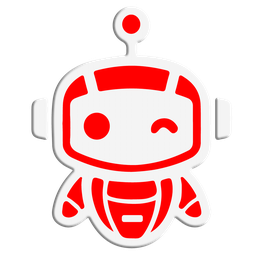
<h2 style="margin:0 0 4px;padding:0;border:0;font-size:23px;line-height:1.2;color:inherit;">Mejorar imágenes con IA</h2>
<p style="margin:0 auto;max-width:560px;opacity:.8;">Restauración y ampliación de fotografías con CodeFormer e HYPIR en Google Colab.</p>
</div>
<div style="display:flex;flex-wrap:wrap;gap:8px;margin-top:18px;">
<div style="flex:1 1 220px;min-width:200px;padding:9px 12px;border:1px solid rgba(66,133,244,.18);border-radius:8px;background:rgba(66,133,244,.05);"><strong style="font-weight:700;opacity:.75;">Plataforma:</strong>&nbsp;<span>Google Colab</span></div>
<div style="flex:1 1 220px;min-width:200px;padding:9px 12px;border:1px solid rgba(66,133,244,.18);border-radius:8px;background:rgba(66,133,244,.05);"><strong style="font-weight:700;opacity:.75;">Entorno:</strong>&nbsp;<span>Python 3 · PyTorch</span></div>
<div style="flex:1 1 220px;min-width:200px;padding:9px 12px;border:1px solid rgba(66,133,244,.18);border-radius:8px;background:rgba(66,133,244,.05);"><strong style="font-weight:700;opacity:.75;">Motores:</strong>&nbsp;<span>CodeFormer · HYPIR · Real-ESRGAN</span></div>
<div style="flex:1 1 220px;min-width:200px;padding:9px 12px;border:1px solid rgba(66,133,244,.18);border-radius:8px;background:rgba(66,133,244,.05);"><strong style="font-weight:700;opacity:.75;">Aceleración:</strong>&nbsp;<span>GPU (recomendada)</span></div>
<div style="flex:1 1 220px;min-width:200px;padding:9px 12px;border:1px solid rgba(66,133,244,.18);border-radius:8px;background:rgba(66,133,244,.05);"><strong style="font-weight:700;opacity:.75;">Almacenamiento:</strong>&nbsp;<span>Google Drive (opcional)</span></div>
</div>
<div style="border-top:1px dashed rgba(128,128,128,.45);margin:18px 0;"></div>
<div align="center" style="text-align:center;">
<div style="margin-bottom:6px;font-size:10px;font-weight:700;letter-spacing:.08em;text-transform:uppercase;opacity:.65;">Desarrollado por</div>
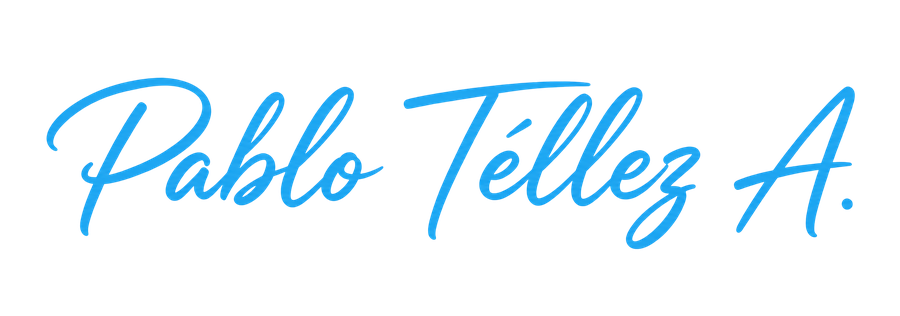
<div style="font-size:12px;opacity:.7;">Tarija · 2026</div>
</div>
</div>
</details>

<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>⚙️ 01 · Preparar el entorno</h2>
</div>

Ejecuta esta celda primero. Prepara las dependencias, CodeFormer y HYPIR, y descarga sus pesos. Google Drive es opcional: si no se monta, puedes subir fotos directamente a Colab y continuar usando el almacenamiento temporal de la sesión. HYPIR también descargará el modelo base Stable Diffusion 2.1 durante su primera ejecución; esto puede tardar y ocupar varios GB.

<blockquote>⏳ La primera ejecución puede tardar unos minutos mientras se preparan los componentes.</blockquote>

Si Google Drive está montado, el código fuente y la caché maestra se conservan allí. Si no está disponible, se guardan en el almacenamiento temporal de Colab y se perderán al terminar la sesión. Para acelerar la carga, SD 2.1 se copia al SSD temporal de Colab una vez por sesión; los pesos se verifican antes de reutilizarlos. La primera preparación necesita conexión para descargar los componentes que falten.


La copia local se valida comparando la revisión fijada y un manifiesto de rutas/tamaños; esto detecta archivos ausentes o truncados sin releer varios GB para calcular hashes. La sustitución de la caché local es transaccional y conserva una copia anterior hasta validar la nueva.


In [ ]:
from pathlib import Path
import os, sys, shutil, subprocess, urllib.request, time, zipfile, hashlib, importlib.metadata, json
from concurrent.futures import ThreadPoolExecutor, as_completed

INICIO_PREPARACION = time.perf_counter()
TIEMPOS_PREPARACION = {}
from PIL import Image, ImageOps
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

PROYECTO = Path('/content/Mejorar_Imagenes_con_IA')
ENTRADA = PROYECTO / 'entrada'
RESULTADOS = PROYECTO / 'resultados'
EXTENSIONES = {
    '.png', '.jpg', '.jpeg', '.webp',
    '.bmp', '.tif', '.tiff',
}

# Google Drive es opcional. Si falla el montaje, el notebook continúa usando
# /content (almacenamiento temporal de Colab); la subida directa de fotos sigue disponible.
EN_COLAB = False
DRIVE_MONTADO = False
files = None
try:
    from google.colab import drive, files
    EN_COLAB = True
except ImportError:
    print('Google Colab no detectado: se trabajará en modo local.')

if EN_COLAB:
    try:
        drive.mount('/content/drive', force_remount=False)
        DRIVE_ROOT = Path('/content/drive/MyDrive')
        if not DRIVE_ROOT.is_dir():
            raise RuntimeError('No existe /content/drive/MyDrive después del montaje.')
        DRIVE_PROYECTO = DRIVE_ROOT / 'Mejorar_Imagenes_con_IA'
        DRIVE_ORIGINALES = DRIVE_PROYECTO / 'originales'
        DRIVE_RESULTADOS = DRIVE_PROYECTO / 'resultados'
        DRIVE_MODELOS = DRIVE_PROYECTO / 'modelos'
        DRIVE_CACHE_HF = DRIVE_PROYECTO / 'cache' / 'huggingface'
        for carpeta in (DRIVE_ORIGINALES, DRIVE_RESULTADOS, DRIVE_MODELOS, DRIVE_CACHE_HF):
            carpeta.mkdir(parents=True, exist_ok=True)
        os.environ['HF_HOME'] = str(DRIVE_CACHE_HF)
        os.environ['HUGGINGFACE_HUB_CACHE'] = str(DRIVE_CACHE_HF / 'hub')
        os.environ['HF_HUB_CACHE'] = str(DRIVE_CACHE_HF / 'hub')
        DRIVE_MONTADO = True
        print('Google Drive montado y carpeta MyDrive verificada.')
    except Exception as e:
        print('\n⚠️ No se pudo montar Google Drive:', repr(e))
        print('Se continuará SIN Drive. Puedes subir las fotos directamente a Colab.')
        print('Los modelos, originales y resultados se guardarán en /content y serán temporales; descarga los resultados antes de cerrar la sesión.\n')

if not DRIVE_MONTADO:
    # Definir rutas de respaldo para que ninguna parte del notebook dependa de Drive.
    DRIVE_PROYECTO = PROYECTO
    DRIVE_ORIGINALES = PROYECTO / 'originales'
    DRIVE_RESULTADOS = RESULTADOS
    DRIVE_MODELOS = PROYECTO / 'modelos'
    DRIVE_CACHE_HF = PROYECTO / 'cache' / 'huggingface'
    for carpeta in (DRIVE_ORIGINALES, DRIVE_RESULTADOS, DRIVE_MODELOS, DRIVE_CACHE_HF):
        carpeta.mkdir(parents=True, exist_ok=True)
    os.environ['HF_HOME'] = str(DRIVE_CACHE_HF)
    os.environ['HUGGINGFACE_HUB_CACHE'] = str(DRIVE_CACHE_HF / 'hub')
    os.environ['HF_HUB_CACHE'] = str(DRIVE_CACHE_HF / 'hub')

for carpeta in (ENTRADA, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Buscar un repositorio ya preparado antes de descargar uno nuevo.
# Congelar el commit que se usa por primera vez para hacer reproducibles
# las sesiones siguientes sin adivinar un hash de CodeFormer.
candidatos_repo = [
    (DRIVE_PROYECTO / 'CodeFormer') if DRIVE_MONTADO else PROYECTO / 'CodeFormer',
    PROYECTO / 'CodeFormer',
    Path('/content/CodeFormer'),
]
CODEFORMER = next(
    (p for p in candidatos_repo
     if (p / 'inference_codeformer.py').is_file()),
    None,
)

if CODEFORMER is None:
    # En Colab, guardar también el repositorio y sus pesos en Drive
    # para que no haya que descargarlos de nuevo en cada sesión.
    CODEFORMER = (
        DRIVE_PROYECTO / 'CodeFormer'
        if DRIVE_MONTADO else PROYECTO / 'CodeFormer'
    )
    respaldo_pesos = CODEFORMER.with_name(CODEFORMER.name + '.weights.tmp')
    pesos_previos = CODEFORMER / 'weights'
    # Restos de una ejecución interrumpida: los pesos se movieron antes de borrar
    # el repositorio y el respaldo no llegó a restaurarse. Recuperarlos o limpiarlos
    # antes de continuar para que no queden huérfanos.
    if respaldo_pesos.is_dir():
        if pesos_previos.is_dir():
            # Ambas copias coexisten (restauración interrumpida a medias):
            # recuperar del respaldo los archivos que falten y descartar el resto.
            for _archivo in respaldo_pesos.rglob('*'):
                if not _archivo.is_file():
                    continue
                _destino = pesos_previos / _archivo.relative_to(respaldo_pesos)
                if not _destino.exists():
                    _destino.parent.mkdir(parents=True, exist_ok=True)
                    shutil.move(str(_archivo), str(_destino))
            shutil.rmtree(respaldo_pesos)
        else:
            pesos_previos.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(str(respaldo_pesos), str(pesos_previos))
    elif respaldo_pesos.exists():
        respaldo_pesos.unlink()
    # Un clon parcial (por ejemplo, sin inference_codeformer.py) puede conservar
    # weights/ ya verificados. Se mueven fuera antes de borrar el repositorio para
    # no volver a descargar cientos de MB; se restauran en el finally.
    if pesos_previos.is_dir():
        shutil.move(str(pesos_previos), str(respaldo_pesos))
    print('Descargando el repositorio oficial de CodeFormer desde la rama predeterminada…')
    try:
        if CODEFORMER.exists():
            shutil.rmtree(CODEFORMER)
        subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/sczhou/CodeFormer.git',
             str(CODEFORMER)],
            check=True,
        )
    finally:
        if respaldo_pesos.is_dir():
            pesos_previos.parent.mkdir(parents=True, exist_ok=True)
            if pesos_previos.exists():
                shutil.rmtree(pesos_previos)
            shutil.move(str(respaldo_pesos), str(pesos_previos))
            print('Pesos de CodeFormer conservados en:', pesos_previos)
else:
    print('Repositorio encontrado:', CODEFORMER)

# Registrar el commit real de CodeFormer. Si ya existe el marcador, exigir que
# el checkout coincida; no cambiarlo silenciosamente porque el notebook puede
# aplicar después un ajuste local a inference_codeformer.py.
MARCADOR_COMMIT_CODEFORMER = (
    DRIVE_PROYECTO / 'cache' / 'codeformer_commit.txt'
    if DRIVE_MONTADO else PROYECTO / 'cache' / 'codeformer_commit.txt'
)
MARCADOR_COMMIT_CODEFORMER.parent.mkdir(parents=True, exist_ok=True)
try:
    commit_codeformer_actual = subprocess.run(
        ['git', '-C', str(CODEFORMER), 'rev-parse', 'HEAD'],
        check=True, capture_output=True, text=True,
    ).stdout.strip()
except (subprocess.CalledProcessError, FileNotFoundError) as e:
    raise RuntimeError(
        'No se pudo identificar el commit del repositorio CodeFormer. '
        'Comprueba que la carpeta sea un clon Git válido.'
    ) from e
if not commit_codeformer_actual:
    raise RuntimeError('Git devolvió un commit vacío para CodeFormer.')
if MARCADOR_COMMIT_CODEFORMER.is_file():
    commit_codeformer_fijado = MARCADOR_COMMIT_CODEFORMER.read_text(encoding='utf-8').strip()
    if commit_codeformer_fijado and commit_codeformer_actual != commit_codeformer_fijado:
        raise RuntimeError(
            'El repositorio CodeFormer cambió respecto al commit fijado. '
            f'Esperado: {commit_codeformer_fijado}; actual: {commit_codeformer_actual}. '
            'No se cambió automáticamente para proteger las modificaciones locales. '
            'Revisa el repositorio antes de continuar.'
        )
else:
    commit_codeformer_fijado = commit_codeformer_actual
    MARCADOR_COMMIT_CODEFORMER.write_text(
        commit_codeformer_fijado + '\n', encoding='utf-8'
    )
print('Commit CodeFormer fijado:', commit_codeformer_fijado[:12])

# Asegurar que los módulos propios de CodeFormer existen y que Python puede localizarlos.
# basicsr y facelib forman parte del código fuente del repositorio en esta revisión;
# no se sustituyen por paquetes externos ni se reinstala todo el entorno para resolverlos.
sys.path.insert(0, str(CODEFORMER))

for _modulo_local in ('basicsr', 'facelib'):
    _ruta_modulo = CODEFORMER / _modulo_local
    if not _ruta_modulo.is_dir():
        # Recuperar únicamente el directorio ausente desde el commit ya fijado.
        # No se elimina el repositorio ni se sobrescriben directorios existentes.
        _comprobacion_git = subprocess.run(
            ['git', '-C', str(CODEFORMER), 'ls-tree', '-d', '--name-only',
             commit_codeformer_fijado, '--', _modulo_local],
            check=True, capture_output=True, text=True,
        ).stdout.splitlines()
        if _modulo_local in _comprobacion_git:
            print(f'Falta {_modulo_local}/; se recuperará desde el commit fijado de CodeFormer.')
            subprocess.run(
                ['git', '-C', str(CODEFORMER), 'checkout',
                 commit_codeformer_fijado, '--', _modulo_local],
                check=True,
            )
        else:
            raise FileNotFoundError(
                f'No existe { _ruta_modulo } y el commit {commit_codeformer_fijado[:12]} '
                f'no contiene el directorio { _modulo_local }.'
            )

# Compatibilidad de algunas copias de BasicSR que no incluyen version.py.
# Solo se crea este archivo auxiliar si el directorio local existe y el archivo falta.
version_py = CODEFORMER / 'basicsr' / 'version.py'
if (CODEFORMER / 'basicsr').is_dir() and not version_py.exists():
    version_py.write_text(
        "__version__ = '0.0.0-local'\n__gitsha__ = 'unknown'\n",
        encoding='utf-8',
    )

# Instalar/comprobar dependencias CodeFormer sin fijar todo el entorno.
# En Colab, PyTorch/torchvision suelen venir preparados para la GPU disponible.
# Se excluyen requisitos directos de torch/torchvision/torchaudio; el código fuente
# de basicsr/facelib se resuelve desde el repositorio local, no con pip.
archivo_requisitos = CODEFORMER / 'requirements.txt'
if not archivo_requisitos.is_file():
    raise FileNotFoundError(
        'No se encontró requirements.txt en el repositorio: '
        + str(archivo_requisitos)
    )

HASH_REQUIREMENTS = hashlib.sha256(archivo_requisitos.read_bytes()).hexdigest()
MARCADOR_CODEFORMER_DEPS = Path(
    f'/content/.mejorar_codeformer_deps_py{sys.version_info.major}{sys.version_info.minor}_{HASH_REQUIREMENTS[:12]}'
)

# Paquetes que no queremos que requirements.txt solicite instalar directamente.
# Se conserva el PyTorch proporcionado por Colab; no se fijan versiones de los demás.
PAQUETES_PROTEGIDOS_COLAB = {'torch', 'torchvision', 'torchaudio'}

def _nombre_paquete_requisito(linea):
    """Extrae de forma conservadora el nombre de un requisito PEP 508 sencillo."""
    import re
    linea = linea.strip()
    if not linea or linea.startswith('#') or linea.startswith('-'):
        return None
    coincidencia = re.match(r'^([A-Za-z0-9][A-Za-z0-9._-]*)', linea)
    return coincidencia.group(1).lower().replace('_', '-') if coincidencia else None

def _requisitos_sin_pytorch(ruta_origen, ruta_destino):
    """Crea un requirements temporal omitiendo torch/torchvision/torchaudio directos."""
    lineas = ruta_origen.read_text(encoding='utf-8').splitlines()
    conservadas = []
    omitidas = []
    for linea in lineas:
        nombre = _nombre_paquete_requisito(linea)
        if nombre in PAQUETES_PROTEGIDOS_COLAB:
            omitidas.append(linea)
        else:
            conservadas.append(linea)
    ruta_destino.write_text('\n'.join(conservadas) + '\n', encoding='utf-8')
    if omitidas:
        print('Se omiten requisitos directos que podrían reemplazar el stack de Colab:')
        for linea in omitidas:
            print('  -', linea)
    return ruta_destino

def _version_stack_torch():
    """Registra las versiones actuales para detectar cambios inesperados."""
    versiones = {}
    for paquete in ('torch', 'torchvision', 'torchaudio'):
        try:
            versiones[paquete] = importlib.metadata.version(paquete)
        except importlib.metadata.PackageNotFoundError:
            versiones[paquete] = None
    return versiones

def _comprobar_imports_codeformer():
    """Comprueba imports esenciales sin asumir versiones concretas."""
    import importlib
    modulos = ('torch', 'torchvision', 'cv2', 'basicsr', 'facelib')
    fallos = []
    for nombre in modulos:
        try:
            importlib.import_module(nombre)
        except Exception as exc:
            fallos.append(f'{nombre}: {type(exc).__name__}: {exc}')
    return fallos

inicio_instalacion_codeformer = time.perf_counter()
fallos_importacion = _comprobar_imports_codeformer() if MARCADOR_CODEFORMER_DEPS.is_file() else ['No existe marcador de dependencias en esta sesión.']
if not fallos_importacion:
    print('Dependencias CodeFormer: el marcador existe y los imports esenciales funcionan; se omite pip install.')
else:
    print('Se comprobarán/instalarán dependencias CodeFormer. Motivo:', '; '.join(fallos_importacion))
    versiones_torch_antes = _version_stack_torch()
    requisitos_temporales = Path('/content/requirements_codeformer_sin_stack_torch.txt')
    _requisitos_sin_pytorch(archivo_requisitos, requisitos_temporales)
    try:
        subprocess.run(
            [
                sys.executable, '-m', 'pip', 'install',
                '--upgrade-strategy', 'only-if-needed',
                '-r', str(requisitos_temporales),
            ],
            check=True,
        )
    finally:
        requisitos_temporales.unlink(missing_ok=True)

    versiones_torch_despues = _version_stack_torch()
    cambios_torch = {
        paquete: (versiones_torch_antes[paquete], versiones_torch_despues[paquete])
        for paquete in versiones_torch_antes
        if versiones_torch_antes[paquete] != versiones_torch_despues[paquete]
    }
    if cambios_torch:
        detalle = ', '.join(
            f'{paquete}: {antes} -> {despues}'
            for paquete, (antes, despues) in cambios_torch.items()
        )
        raise RuntimeError(
            'La resolución de dependencias cambió el stack de PyTorch de Colab '
            f'({detalle}). Se detiene la preparación para evitar continuar con '
            'un entorno potencialmente incompatible. Reinicia el runtime de Colab '
            'si la GPU dejó de funcionar y revisa el requirements.txt del repositorio.'
        )

    fallos_importacion = _comprobar_imports_codeformer()
    if fallos_importacion:
        raise RuntimeError(
            'La instalación terminó, pero fallan imports esenciales de CodeFormer:\n'
            + '\n'.join(fallos_importacion)
            + '\nNo se marcará la instalación como válida.'
        )
    # Escribir el marcador solo después de comprobar los imports.
    MARCADOR_CODEFORMER_DEPS.write_text(
        f'requirements_sha256={HASH_REQUIREMENTS}\n'
        f'torch_stack={json.dumps(versiones_torch_despues, sort_keys=True)}\n',
        encoding='utf-8',
    )
    print('Dependencias CodeFormer instaladas y comprobadas.')
TIEMPOS_PREPARACION['Dependencias CodeFormer (instalar/comprobar)'] = time.perf_counter() - inicio_instalacion_codeformer

SCRIPT = CODEFORMER / 'inference_codeformer.py'
if not SCRIPT.is_file():
    mensaje = 'No se encontró inference_codeformer.py en '
    raise FileNotFoundError(mensaje + str(CODEFORMER))

# Algunas copias no incluyen version.py.
# BasicSR lo importa al iniciar.
version_py = CODEFORMER / 'basicsr' / 'version.py'
if (CODEFORMER / 'basicsr').is_dir() and not version_py.exists():
    version_py.write_text(
        "__version__ = '0.0.0-local'\n__gitsha__ = 'unknown'\n",
        encoding='utf-8',
    )

# Confirmación final: los módulos propios deben poder importarse incluso si había marcador.
import importlib
fallos_modulos_codeformer = []
for nombre_modulo in ('basicsr', 'facelib'):
    try:
        importlib.import_module(nombre_modulo)
    except Exception as exc:
        fallos_modulos_codeformer.append(
            f'{nombre_modulo}: {type(exc).__name__}: {exc}'
        )
if fallos_modulos_codeformer:
    raise RuntimeError(
        'Los módulos locales de CodeFormer siguen sin poder importarse. '
        'Comprueba que el repositorio esté completo y que no haya errores internos:\n'
        + '\n'.join(fallos_modulos_codeformer)
    )

# Descargar pesos desde nuestro propio GitHub Release.
# Se verifica SHA-256 para detectar descargas incompletas o archivos alterados.
import hashlib
inicio_descarga_pesos_codeformer = time.perf_counter()

BASE_URL = (
    'https://github.com/Pablitus666/Mejorar_Imagenes_con_IA/'
    'releases/download/modelos-v1/'
)

PESO_CODEFORMER = (
    CODEFORMER / 'weights' / 'CodeFormer' / 'codeformer.pth'
)
PESO_DETECCION = (
    CODEFORMER / 'weights' / 'facelib'
    / 'detection_Resnet50_Final.pth'
)
PESO_PARSING = CODEFORMER / 'weights' / 'facelib' / 'parsing_parsenet.pth'
PESO_YOLO = CODEFORMER / 'weights' / 'facelib' / 'yolov5l-face.pth'

PESOS = [
    {
        'nombre': 'codeformer.pth',
        'url': BASE_URL + 'codeformer.pth',
        'destino': PESO_CODEFORMER,
        'minimo_bytes': 100_000_000,
        'sha256': '1009e537e0c2a07d4cabce6355f53cb66767cd4b4297ec7a4a64ca4b8a5684b7',
    },
    {
        'nombre': 'detection_Resnet50_Final.pth',
        'url': BASE_URL + 'detection_Resnet50_Final.pth',
        'destino': PESO_DETECCION,
        'minimo_bytes': 1_000_000,
        'sha256': '6d1de9c2944f2ccddca5f5e010ea5ae64a39845a86311af6fdf30841b0a5a16d',
    },
    {
        'nombre': 'parsing_parsenet.pth',
        'url': BASE_URL + 'parsing_parsenet.pth',
        'destino': PESO_PARSING,
        'minimo_bytes': 1_000_000,
        'sha256': '3d558d8d0e42c20224f13cf5a29c79eba2d59913419f945545d8cf7b72920de2',
    },
    {
        'nombre': 'RealESRGAN_x2plus.pth',
        'url': BASE_URL + 'RealESRGAN_x2plus.pth',
        'destino': CODEFORMER / 'weights' / 'realesrgan' / 'RealESRGAN_x2plus.pth',
        'minimo_bytes': 60_000_000,
        'sha256': '49fafd45f8fd7aa8d31ab2a22d14d91b536c34494a5cfe31eb5d89c2fa266abb',
    },
    {
        'nombre': 'yolov5l-face.pth',
        'url': BASE_URL + 'yolov5l-face.pth',
        'destino': PESO_YOLO,
        'minimo_bytes': 100_000_000,
        'sha256': '1ba9d2125fda4d823df5152b9fc2903c59aa76c0d3771e02bcf13a56a282cf96',
    },
]

def calcular_sha256(ruta):
    sha = hashlib.sha256()
    with open(ruta, 'rb') as archivo:
        for bloque in iter(lambda: archivo.read(4 * 1024 * 1024), b''):
            sha.update(bloque)
    return sha.hexdigest()


# Caché persistente de verificaciones (v2). La firma usa ruta, tamaño, mtime
# y hash esperado. ctime e inode NO se usan: cambian en cada montaje de Google
# Drive (FUSE) e invalidaban la caché en cada sesión. Si cambia el mtime, se
# compara antes una huella parcial (primer y último MiB) para no releer todo.
CACHE_SHA_VERSION = 2
CACHE_SHA_DIR = (
    DRIVE_PROYECTO / 'cache' / 'verificaciones_sha256'
    if DRIVE_MONTADO else PROYECTO / 'cache' / 'verificaciones_sha256'
)
CACHE_SHA_DIR.mkdir(parents=True, exist_ok=True)

def huella_parcial(ruta, bloque=1024 * 1024):
    """Huella barata: tamaño + primer y último bloque (≈2 MB como máximo)."""
    tamano = ruta.stat().st_size
    sha = hashlib.sha256(str(tamano).encode('utf-8'))
    with open(ruta, 'rb') as archivo:
        sha.update(archivo.read(bloque))
        if tamano > 2 * bloque:
            archivo.seek(-bloque, os.SEEK_END)
            sha.update(archivo.read(bloque))
        elif tamano > bloque:
            archivo.seek(bloque)
            sha.update(archivo.read(bloque))
    return sha.hexdigest()

def sha256_verificado_cacheable(ruta, sha256_esperado):
    ruta = Path(ruta).resolve()
    stat = ruta.stat()
    clave = hashlib.sha256(str(ruta).encode('utf-8')).hexdigest()[:24]
    marcador = CACHE_SHA_DIR / f'{clave}.json'
    firma = {
        'version': CACHE_SHA_VERSION,
        'ruta': str(ruta),
        'size': stat.st_size,
        'mtime_ns': stat.st_mtime_ns,
        'sha256_esperado': sha256_esperado.lower(),
    }
    try:
        datos = json.loads(marcador.read_text(encoding='utf-8'))
        if (
            datos.get('version') == CACHE_SHA_VERSION
            and datos.get('sha256')
            and all(
                datos.get(k) == firma[k]
                for k in ('ruta', 'size', 'sha256_esperado')
            )
        ):
            if datos.get('mtime_ns') == firma['mtime_ns']:
                return datos['sha256']
            if datos.get('huella') == huella_parcial(ruta):
                return datos['sha256']
    except (OSError, ValueError, TypeError):
        pass
    digest = calcular_sha256(ruta).lower()
    if digest == sha256_esperado.lower():
        firma['sha256'] = digest
        firma['huella'] = huella_parcial(ruta)
        temporal = marcador.with_suffix('.tmp')
        temporal.write_text(json.dumps(firma), encoding='utf-8')
        temporal.replace(marcador)
    return digest

def descargar_peso(url, destino, minimo_bytes, sha256_esperado):
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)

    if destino.is_file() and destino.stat().st_size >= minimo_bytes:
        print(f'Verificando peso existente: {destino.name}…')
        sha_existente = sha256_verificado_cacheable(destino, sha256_esperado)
        if sha_existente.lower() == sha256_esperado.lower():
            print(f'Peso verificado: {destino.name} (SHA-256 correcto)')
            return
        print(f'El SHA-256 de {destino.name} no coincide; se descargará de nuevo.')

    temporal = destino.with_suffix(destino.suffix + '.part')
    if temporal.exists():
        temporal.unlink()
    print(f'Descargando {destino.name} desde nuestro Release…')
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=90) as respuesta, open(temporal, 'wb') as salida:
            total = int(respuesta.headers.get('Content-Length', '0') or 0)
            descargado = 0
            while True:
                bloque = respuesta.read(1024 * 1024)
                if not bloque:
                    break
                salida.write(bloque)
                descargado += len(bloque)
                if total:
                    print(f'  {descargado / total:.0%}', end='\r')

        tamano = temporal.stat().st_size
        if tamano < minimo_bytes:
            raise RuntimeError(
                f'El archivo descargado es demasiado pequeño ({tamano:,} bytes).'
            )
        sha_descargado = calcular_sha256(temporal)
        if sha_descargado.lower() != sha256_esperado.lower():
            raise RuntimeError(
                'La verificación SHA-256 ha fallado. '
                f'Esperado: {sha256_esperado}; obtenido: {sha_descargado}'
            )
        temporal.replace(destino)
        print(f'Verificado y guardado: {destino.name} ({tamano:,} bytes)')
    except Exception as e:
        if temporal.exists():
            temporal.unlink()
        raise RuntimeError(
            f'No se pudo descargar/verificar {destino.name} desde {url}. Detalle: {e}'
        ) from e

for peso in PESOS:
    descargar_peso(
        peso['url'], peso['destino'], peso['minimo_bytes'], peso['sha256']
    )

# Configurar CodeFormer para usar el peso RealESRGAN local.
# La URL oficial puede variar según la revisión del script (CodeFormer o Real-ESRGAN).
# Sustituimos cualquier URL HTTP(S) que termine en RealESRGAN_x2plus.pth,
# sin depender de la versión del dominio ni de la función que la contiene.
import re

PESO_REALESRGAN = (
    CODEFORMER / 'weights' / 'realesrgan' / 'RealESRGAN_x2plus.pth'
).resolve()
ruta_local_script = str(PESO_REALESRGAN)
contenido_script = SCRIPT.read_text(encoding='utf-8')

# Guardar una copia del script original una sola vez.
copia_seguridad = SCRIPT.with_suffix(SCRIPT.suffix + '.bak')
if not copia_seguridad.exists():
    shutil.copy2(SCRIPT, copia_seguridad)

# Ejemplo de URL oficial que se corrige:
# https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth
patron_url_realesrgan = re.compile(
    r"https?://[^\s\"']*RealESRGAN_x2plus\.pth",
    flags=re.IGNORECASE,
)
contenido_corregido, reemplazos = patron_url_realesrgan.subn(
    lambda _m: ruta_local_script,
    contenido_script,
)

if reemplazos:
    SCRIPT.write_text(contenido_corregido, encoding='utf-8')
    print(
        'URL externa de RealESRGAN sustituida por la ruta local '
        f'({reemplazos} reemplazo(s)).'
    )
elif ruta_local_script in contenido_script:
    print('CodeFormer ya estaba configurado para usar el RealESRGAN local.')
else:
    lineas_relevantes = [
        f'{n}: {linea.strip()}'
        for n, linea in enumerate(contenido_script.splitlines(), 1)
        if 'RealESRGAN' in linea or 'model_path' in linea
    ]
    raise RuntimeError(
        'No se encontró la URL de RealESRGAN_x2plus.pth en el script. '
        'No se modificó el script. Líneas relacionadas: '
        + (' | '.join(lineas_relevantes) or '(ninguna)')
    )

# Verificar que la URL externa ya no aparece y que el archivo local sí.
contenido_final = SCRIPT.read_text(encoding='utf-8')
if ruta_local_script not in contenido_final:
    raise RuntimeError(
        'La verificación de la ruta local de RealESRGAN falló: ' + str(SCRIPT)
    )
if patron_url_realesrgan.search(contenido_final):
    raise RuntimeError(
        'Todavía queda una URL externa de RealESRGAN_x2plus.pth en ' + str(SCRIPT)
    )
if not PESO_REALESRGAN.is_file() or PESO_REALESRGAN.stat().st_size == 0:
    raise FileNotFoundError(
        'No existe el peso local de RealESRGAN o está vacío: '
        + str(PESO_REALESRGAN)
    )

# Garantizar que desmarcar "Mejorar también el fondo" desactive
# RealESRGAN incluso si se reutiliza una copia cuyo valor predeterminado
# lo activa. La celda de restauración solo añade --bg_upsampler realesrgan
# cuando la opción está marcada.
patron_argumento_fondo = re.compile(
    r"(?m)^(?P<prefijo>\s*parser\.add_argument\(\s*['\"]--bg_upsampler['\"][^\n]*?\bdefault\s*=\s*)"
    r"['\"](?P<valor>[^'\"]*)['\"]"
)
coincidencia_fondo = patron_argumento_fondo.search(contenido_final)
if coincidencia_fondo and coincidencia_fondo.group('valor').lower() == 'realesrgan':
    contenido_final = patron_argumento_fondo.sub(
        lambda m: m.group('prefijo') + "'None'",
        contenido_final,
        count=1,
    )
    SCRIPT.write_text(contenido_final, encoding='utf-8')
    print('Control de fondo ajustado: RealESRGAN queda desactivado por defecto.')
elif coincidencia_fondo:
    print(
        'Control de fondo verificado: valor predeterminado =',
        repr(coincidencia_fondo.group('valor')),
    )
else:
    # Si no se declara un valor predeterminado explícito, argparse usa None.
    linea_bg = next(
        (linea.strip() for linea in contenido_final.splitlines()
         if '--bg_upsampler' in linea),
        None,
    )
    if linea_bg is None:
        raise RuntimeError(
            'No se encontró el argumento --bg_upsampler en CodeFormer; '
            'no es posible garantizar el control de mejora del fondo.'
        )
    if re.search(r"default\s*=\s*['\"]?realesrgan", linea_bg, re.IGNORECASE):
        raise RuntimeError(
            'CodeFormer activa RealESRGAN por defecto y no se pudo ajustar '
            'automáticamente el argumento --bg_upsampler.'
        )
    print('Control de fondo verificado en el argumento:', linea_bg)

print('Peso RealESRGAN local:', PESO_REALESRGAN)
print('Verificación SHA-256: ya realizada durante la descarga de pesos.')
TIEMPOS_PREPARACION['Pesos CodeFormer/Real-ESRGAN (comprobación/descarga)'] = time.perf_counter() - inicio_descarga_pesos_codeformer

# ------------------------------------------------------------
# Preparar HYPIR con código fuente cacheado en Drive.
# Se conserva el PyTorch de Colab y se fija una revisión conocida
# para que cambios futuros en la rama main no alteren el resultado.
# ------------------------------------------------------------
HYPIR_REVISION = 'b61d107'
HYPIR_REPO = PROYECTO / 'HYPIR'  # código extraído en disco local de Colab
HYPIR_SCRIPT = HYPIR_REPO / 'test.py'
HYPIR_REVISION_FILE = HYPIR_REPO / '.mejorar_hypir_revision'
HYPIR_PESO = (
    DRIVE_MODELOS / 'HYPIR_sd2.pth'
    if DRIVE_MONTADO else PROYECTO / 'modelos' / 'HYPIR_sd2.pth'
)
HYPIR_PESO.parent.mkdir(parents=True, exist_ok=True)
CACHE_CODIGO_HYPIR = (
    DRIVE_PROYECTO / 'cache' / 'codigo_hypir'
    if DRIVE_MONTADO else PROYECTO / 'cache' / 'codigo_hypir'
)
CACHE_CODIGO_HYPIR.mkdir(parents=True, exist_ok=True)
HYPIR_ARCHIVO = CACHE_CODIGO_HYPIR / f'HYPIR_{HYPIR_REVISION}.zip'
HYPIR_URL_ARCHIVO = (
    f'https://github.com/XPixelGroup/HYPIR/archive/{HYPIR_REVISION}.zip'
)

# La primera sesión descarga un ZIP pequeño y lo conserva en Drive.
# En sesiones posteriores se extrae localmente, evitando clonar GitHub otra vez.
def archivo_hypir_valido(ruta_zip):
    try:
        with zipfile.ZipFile(ruta_zip, 'r') as zf:
            nombres = zf.namelist()
            return (
                zf.testzip() is None
                and any(n.endswith('/test.py') for n in nombres)
                and any(n.endswith('/HYPIR/enhancer/sd2.py') for n in nombres)
            )
    except (OSError, zipfile.BadZipFile):
        return False

inicio_codigo_hypir = time.perf_counter()
if (not HYPIR_SCRIPT.is_file() or not HYPIR_REVISION_FILE.is_file()
        or HYPIR_REVISION_FILE.read_text(encoding='utf-8').strip() != HYPIR_REVISION):
    if not archivo_hypir_valido(HYPIR_ARCHIVO):
        if HYPIR_ARCHIVO.exists():
            HYPIR_ARCHIVO.unlink()
        temporal_zip = HYPIR_ARCHIVO.with_suffix('.zip.part')
        print(f'Descargando código HYPIR {HYPIR_REVISION} para guardarlo en caché…')
        req = urllib.request.Request(
            HYPIR_URL_ARCHIVO,
            headers={'User-Agent': 'Mejorar-Imagenes-con-IA'},
        )
        try:
            with urllib.request.urlopen(req, timeout=90) as respuesta, open(temporal_zip, 'wb') as salida:
                shutil.copyfileobj(respuesta, salida)
            if not archivo_hypir_valido(temporal_zip):
                raise RuntimeError('El ZIP de HYPIR descargado no pasó la verificación.')
            temporal_zip.replace(HYPIR_ARCHIVO)
        except Exception:
            if temporal_zip.exists():
                temporal_zip.unlink()
            raise
    else:
        print('Archivo fuente HYPIR verificado en caché:', HYPIR_ARCHIVO)

    # Extraer en el disco temporal de Colab para acelerar los imports de Python.
    carpeta_extraccion = PROYECTO / '_extraccion_hypir'
    if carpeta_extraccion.exists():
        shutil.rmtree(carpeta_extraccion)
    carpeta_extraccion.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(HYPIR_ARCHIVO, 'r') as zf:
        # Rechazar rutas extrañas antes de extraer el archivo.
        raiz = carpeta_extraccion.resolve()
        for miembro in zf.infolist():
            destino_miembro = (carpeta_extraccion / miembro.filename).resolve()
            if destino_miembro != raiz and raiz not in destino_miembro.parents:
                raise RuntimeError('El ZIP de HYPIR contiene una ruta no válida.')
        zf.extractall(carpeta_extraccion)
    carpetas_fuente = [p for p in carpeta_extraccion.iterdir() if p.is_dir()]
    raiz_fuente = next((p for p in carpetas_fuente if (p / 'test.py').is_file()), None)
    if raiz_fuente is None or not (raiz_fuente / 'HYPIR' / 'enhancer' / 'sd2.py').is_file():
        raise FileNotFoundError('La fuente extraída de HYPIR no tiene la estructura esperada.')
    if HYPIR_REPO.exists():
        shutil.rmtree(HYPIR_REPO)
    raiz_fuente.replace(HYPIR_REPO)
    HYPIR_REVISION_FILE.write_text(HYPIR_REVISION + '\n', encoding='utf-8')
    shutil.rmtree(carpeta_extraccion, ignore_errors=True)
else:
    print('Código HYPIR disponible en el entorno:', HYPIR_SCRIPT, '(revisión', HYPIR_REVISION + ')')
TIEMPOS_PREPARACION['Código HYPIR (caché/descarga/extracción)'] = time.perf_counter() - inicio_codigo_hypir

if not (HYPIR_REPO / 'LICENSE').is_file():
    print('Aviso: no se encontró el archivo LICENSE de HYPIR en la copia local.')

# Las versiones se fijan para reproducibilidad. Si ya están correctas en este
# runtime, no se vuelve a ejecutar pip (evita resolución e instalaciones repetidas).
DEPENDENCIAS_HYPIR = {
    'accelerate': '1.4.0',
    'diffusers': '0.32.2',
    'transformers': '4.49.0',
    'peft': '0.14.0',
    'einops': '0.8.1',
    'omegaconf': '2.3.0',
    'timm': '1.0.15',
    'huggingface-hub': '0.36.0',
}
def dependencias_hypir_correctas():
    try:
        return all(
            importlib.metadata.version(paquete) == version
            for paquete, version in DEPENDENCIAS_HYPIR.items()
        )
    except importlib.metadata.PackageNotFoundError:
        return False

inicio_instalacion_hypir = time.perf_counter()
MARCADOR_HYPIR_DEPS = Path(
    f'/content/.mejorar_hypir_deps_py{sys.version_info.major}{sys.version_info.minor}'
)
if dependencias_hypir_correctas():
    print('Dependencias HYPIR ya están en las versiones fijadas; se omite pip install.')
else:
    print('Instalando/comprobando dependencias HYPIR sin reemplazar PyTorch…')
    subprocess.run([
        sys.executable, '-m', 'pip', 'install', '-q',
        'accelerate==1.4.0', 'diffusers==0.32.2',
        'transformers==4.49.0', 'peft==0.14.0',
        'einops==0.8.1', 'omegaconf==2.3.0', 'timm==1.0.15',
        'huggingface_hub==0.36.0',
    ], check=True)
    if not dependencias_hypir_correctas():
        raise RuntimeError('Las dependencias HYPIR no coinciden con las versiones fijadas tras instalarlas.')
    MARCADOR_HYPIR_DEPS.write_text('dependencias_verificadas\n', encoding='utf-8')
TIEMPOS_PREPARACION['Dependencias HYPIR (instalar/comprobar)'] = time.perf_counter() - inicio_instalacion_hypir

# El peso se fija a una revisión concreta y se verifica por SHA-256.
# Así se detectan archivos truncados o alterados antes de iniciar la inferencia.
HYPIR_PESO_SHA256 = 'd538a2cb925451fab1f75adfe715ac2b1c8bb12fa32a0851ba01be2347b354d6'
HYPIR_PESO_REVISION = '93e4cceb10df58bb5d2441159f6abd4cf56430ba'
inicio_peso_hypir = time.perf_counter()
peso_correcto = (
    HYPIR_PESO.is_file()
    and HYPIR_PESO.stat().st_size > 500_000_000
    and sha256_verificado_cacheable(HYPIR_PESO, HYPIR_PESO_SHA256).lower() == HYPIR_PESO_SHA256
)
if not peso_correcto:
    if HYPIR_PESO.exists():
        print('El peso HYPIR local falta o no supera SHA-256; se volverá a descargar.')
        HYPIR_PESO.unlink()
    print('Descargando los pesos HYPIR (aprox. 1 GB) desde una revisión fijada…')
    from huggingface_hub import hf_hub_download
    peso_cache = Path(hf_hub_download(
        repo_id='lxq007/HYPIR',
        filename='HYPIR_sd2.pth',
        revision=HYPIR_PESO_REVISION,
        local_dir=str(HYPIR_PESO.parent),
    ))
    if peso_cache.resolve() != HYPIR_PESO.resolve():
        shutil.copy2(peso_cache, HYPIR_PESO)
    if calcular_sha256(HYPIR_PESO).lower() != HYPIR_PESO_SHA256:
        raise RuntimeError('El peso HYPIR descargado no coincide con el SHA-256 esperado.')
    print('Peso HYPIR descargado y verificado por SHA-256.')
else:
    print('Peso HYPIR encontrado y verificado:', HYPIR_PESO)
TIEMPOS_PREPARACION['Peso HYPIR (SHA-256/comprobación/descarga)'] = time.perf_counter() - inicio_peso_hypir

def resumen_arbol_archivos(raiz):
    """Resumen reproducible de rutas y tamaños; no lee el contenido de los pesos."""
    raiz = Path(raiz)
    entradas = []
    for ruta in raiz.rglob('*'):
        relativa = ruta.relative_to(raiz)
        if ('.cache' in relativa.parts
                or relativa.name in {'.mejorar_cache_completa', '.mejorar_cache_completa.tmp'}):
            continue
        if ruta.is_file():
            entradas.append((relativa.as_posix(), ruta.stat().st_size))
    entradas.sort()
    serializado = ''.join(f'{nombre}\t{tamano}\n' for nombre, tamano in entradas)
    return {
        'archivos': len(entradas),
        'bytes': sum(tamano for _, tamano in entradas),
        'sha256_manifest': hashlib.sha256(serializado.encode('utf-8')).hexdigest(),
        'entradas': entradas,
    }


def copiar_arbol_paralelo(origen, destino, trabajadores=None):
    """Copia al SSD en paralelo y verifica ruta/tamaño de cada archivo copiado."""
    origen, destino = Path(origen), Path(destino)
    resumen_origen = resumen_arbol_archivos(origen)
    archivos = [(origen / relativa, destino / relativa)
                for relativa, _ in resumen_origen['entradas']]
    # Evitar una cola enorme y aprovechar concurrencia en los archivos grandes,
    # sin abrir más de ocho copias simultáneas sobre Google Drive/FUSE.
    if trabajadores is None:
        trabajadores = min(8, max(1, len(archivos)))
    trabajadores = max(1, min(int(trabajadores), max(1, len(archivos)), 8))
    for ruta in origen.rglob('*'):
        relativa = ruta.relative_to(origen)
        if '.cache' in relativa.parts:
            continue
        if ruta.is_dir():
            (destino / relativa).mkdir(parents=True, exist_ok=True)
    destino.mkdir(parents=True, exist_ok=True)
    errores = []
    with ThreadPoolExecutor(max_workers=trabajadores) as pool:
        futuros = [pool.submit(shutil.copy2, origen_archivo, destino_archivo)
                   for origen_archivo, destino_archivo in archivos]
        for futuro in as_completed(futuros):
            try:
                futuro.result()
            except Exception as exc:
                errores.append(exc)
    if errores:
        raise RuntimeError(
            f'Fallaron {len(errores)} archivos durante la copia paralela: {errores[0]}'
        )
    resumen_destino = resumen_arbol_archivos(destino)
    if (resumen_destino['archivos'] != resumen_origen['archivos']
            or resumen_destino['bytes'] != resumen_origen['bytes']
            or resumen_destino['sha256_manifest'] != resumen_origen['sha256_manifest']):
        raise RuntimeError(
            'La copia SD 2.1 no coincide con el manifiesto de origen '
            '(rutas o tamaños distintos); no se marcará como válida.'
        )
    return resumen_origen, trabajadores


# Acelerar la carga de SD 2.1: conservar la caché maestra en Drive, pero cargar
# desde el SSD local de Colab. La primera descarga fija el commit real de HF;
# las sesiones posteriores reutilizan esa revisión inmutable.
HYPIR_BASE_MODEL_ID = 'STHCD/stable-diffusion-2-1-base'
HYPIR_BASE_MODEL_LOCAL = PROYECTO / '_cache_local' / 'stable-diffusion-2-1-base'
HYPIR_BASE_MODEL_MARKER = HYPIR_BASE_MODEL_LOCAL / '.mejorar_cache_completa'
HYPIR_BASE_MODEL_LOCAL.parent.mkdir(parents=True, exist_ok=True)
HYPIR_BASE_REVISION_FILE = (
    DRIVE_PROYECTO / 'cache' / 'stable-diffusion-2-1-base.revision'
    if EN_COLAB else PROYECTO / 'cache' / 'stable-diffusion-2-1-base.revision'
)
HYPIR_BASE_REVISION_FILE.parent.mkdir(parents=True, exist_ok=True)


def modelo_sd21_valido(raiz):
    """Comprueba configuración y pesos esenciales de un snapshot SD 2.1."""
    raiz = Path(raiz)
    configuraciones = (
        'model_index.json',
        'scheduler/scheduler_config.json',
        'text_encoder/config.json',
        'tokenizer/tokenizer_config.json',
        'unet/config.json',
        'vae/config.json',
    )
    if not raiz.is_dir() or not all((raiz / rel).is_file() for rel in configuraciones):
        return False
    tokenizer = raiz / 'tokenizer'
    if not ((tokenizer / 'tokenizer.json').is_file()
            or ((tokenizer / 'vocab.json').is_file() and (tokenizer / 'merges.txt').is_file())):
        return False
    for componente in ('text_encoder', 'unet', 'vae'):
        carpeta = raiz / componente
        pesos = [p for patron in ('*.safetensors', '*.bin') for p in carpeta.glob(patron)
                 if p.is_file() and p.stat().st_size > 1024]
        if not pesos:
            return False
    try:
        with open(raiz / 'model_index.json', encoding='utf-8') as f:
            indice = json.load(f)
        if not isinstance(indice, dict) or not indice:
            return False
    except (OSError, ValueError, TypeError):
        return False
    return True


def revision_snapshot_hf(ruta_snapshot):
    """Obtiene el hash de commit del directorio snapshots/<commit> de HF."""
    ruta_snapshot = Path(ruta_snapshot).resolve()
    revision = ruta_snapshot.name
    if len(revision) < 7 or not all(c in '0123456789abcdef' for c in revision.lower()):
        raise RuntimeError(
            'No se pudo identificar el commit del snapshot Hugging Face: '
            f'{ruta_snapshot}'
        )
    return revision


inicio_cache_base = time.perf_counter()
from huggingface_hub import snapshot_download
cache_hub = os.environ.get('HF_HUB_CACHE')
revision_base_fijada = (
    HYPIR_BASE_REVISION_FILE.read_text(encoding='utf-8').strip()
    if HYPIR_BASE_REVISION_FILE.is_file() else ''
)
ruta_snapshot_base = None
inicio_busqueda_hf = time.perf_counter()

# Si ya fijamos una revisión, solo se acepta ese snapshot. Si aún no existe
# marcador, primero se intenta descubrir una revisión ya cacheada localmente.
if revision_base_fijada:
    try:
        ruta_candidata = Path(snapshot_download(
            repo_id=HYPIR_BASE_MODEL_ID,
            revision=revision_base_fijada,
            cache_dir=cache_hub,
            local_files_only=True,
        ))
        if modelo_sd21_valido(ruta_candidata):
            ruta_snapshot_base = ruta_candidata
            print('Snapshot SD 2.1 de revisión fijada encontrado en la caché persistente.')
    except Exception as e_cache:
        print('La revisión fijada no está completa en la caché local:', str(e_cache)[:250])
else:
    try:
        ruta_candidata = Path(snapshot_download(
            repo_id=HYPIR_BASE_MODEL_ID,
            cache_dir=cache_hub,
            local_files_only=True,
        ))
        if modelo_sd21_valido(ruta_candidata):
            ruta_snapshot_base = ruta_candidata
            revision_base_fijada = revision_snapshot_hf(ruta_candidata)
            HYPIR_BASE_REVISION_FILE.write_text(revision_base_fijada + '\n', encoding='utf-8')
            print('Se fijó la revisión ya almacenada en la caché de Hugging Face.')
    except Exception as e_cache:
        print('No hay snapshot SD 2.1 completo en la caché local:', str(e_cache)[:250])

if ruta_snapshot_base is None:
    inicio_descarga_base = time.perf_counter()
    print('Descargando/comprobando el modelo base SD 2.1 desde Hugging Face…')
    argumentos_descarga = {
        'repo_id': HYPIR_BASE_MODEL_ID,
        'cache_dir': cache_hub,
        'local_files_only': False,
    }
    if revision_base_fijada:
        argumentos_descarga['revision'] = revision_base_fijada
    ruta_snapshot_base = Path(snapshot_download(**argumentos_descarga))
    if not modelo_sd21_valido(ruta_snapshot_base):
        raise FileNotFoundError(
            'Hugging Face devolvió un snapshot SD 2.1 incompleto: faltan configuraciones o pesos esenciales. '
            f'Ruta: {ruta_snapshot_base}'
        )
    revision_descargada = revision_snapshot_hf(ruta_snapshot_base)
    if revision_base_fijada and revision_descargada != revision_base_fijada:
        raise RuntimeError(
            'La revisión descargada no coincide con la fijada: '
            f'{revision_descargada} != {revision_base_fijada}'
        )
    revision_base_fijada = revision_descargada
    HYPIR_BASE_REVISION_FILE.write_text(revision_base_fijada + '\n', encoding='utf-8')
    TIEMPOS_PREPARACION['Modelo base: descarga/comprobación HF'] = time.perf_counter() - inicio_descarga_base
else:
    TIEMPOS_PREPARACION['Modelo base: descarga/comprobación HF'] = time.perf_counter() - inicio_busqueda_hf

# Comparar también un manifiesto ligero de rutas y tamaños. Así se detectan
# copias truncadas o incompletas sin volver a leer varios GB para calcular hashes.
if not modelo_sd21_valido(ruta_snapshot_base):
    raise FileNotFoundError('El snapshot SD 2.1 de origen no superó la validación previa a la copia.')
resumen_snapshot = resumen_arbol_archivos(ruta_snapshot_base)
if resumen_snapshot['archivos'] == 0 or resumen_snapshot['bytes'] == 0:
    raise RuntimeError('El snapshot SD 2.1 no contiene archivos copiables.')
marcador_esperado = (
    f'repo={HYPIR_BASE_MODEL_ID}\nrevision={revision_base_fijada}\n'
    f"archivos={resumen_snapshot['archivos']}\n"
    f"bytes={resumen_snapshot['bytes']}\n"
    f"manifest_sha256={resumen_snapshot['sha256_manifest']}\n"
)
marcador_local_actual = (
    HYPIR_BASE_MODEL_MARKER.read_text(encoding='utf-8')
    if HYPIR_BASE_MODEL_MARKER.is_file() else ''
)
resumen_local = (
    resumen_arbol_archivos(HYPIR_BASE_MODEL_LOCAL)
    if HYPIR_BASE_MODEL_LOCAL.is_dir() else None
)
local_coincide = bool(
    resumen_local
    and resumen_local['archivos'] == resumen_snapshot['archivos']
    and resumen_local['bytes'] == resumen_snapshot['bytes']
    and resumen_local['sha256_manifest'] == resumen_snapshot['sha256_manifest']
)
if (modelo_sd21_valido(HYPIR_BASE_MODEL_LOCAL)
        and marcador_local_actual == marcador_esperado and local_coincide):
    print(
        'Modelo base SD 2.1 validado en SSD local: revisión, manifiesto, '
        'cantidad de archivos y tamaños coinciden; se omite la copia.'
    )
    TIEMPOS_PREPARACION['Modelo base: copia a SSD local'] = 0.0
else:
    staging_base = HYPIR_BASE_MODEL_LOCAL.parent / '_stable-diffusion-2-1-base.tmp'
    respaldo_base = HYPIR_BASE_MODEL_LOCAL.parent / '_stable-diffusion-2-1-base.previous'
    if staging_base.exists():
        shutil.rmtree(staging_base)
    if respaldo_base.exists():
        shutil.rmtree(respaldo_base)
    inicio_copia_base = time.perf_counter()
    print(
        'Copiando SD 2.1 desde la caché persistente al SSD local '
        f'({resumen_snapshot["archivos"]} archivos, '
        f'{resumen_snapshot["bytes"] / (1024**3):.2f} GiB)…'
    )
    try:
        resumen_copiado, trabajadores_usados = copiar_arbol_paralelo(
            ruta_snapshot_base, staging_base, trabajadores=None
        )
        if not modelo_sd21_valido(staging_base):
            raise FileNotFoundError(
                'La copia local de SD 2.1 no superó la validación de configuraciones y pesos.'
            )
        if (resumen_copiado['sha256_manifest'] != resumen_snapshot['sha256_manifest']
                or resumen_copiado['bytes'] != resumen_snapshot['bytes']):
            raise RuntimeError('El manifiesto de la copia SD 2.1 no coincide con el origen.')

        # Sustitución con rollback: conservar la copia anterior hasta que la nueva
        # esté verificada y el marcador se haya escrito correctamente.
        if HYPIR_BASE_MODEL_LOCAL.exists():
            HYPIR_BASE_MODEL_LOCAL.rename(respaldo_base)
        try:
            staging_base.rename(HYPIR_BASE_MODEL_LOCAL)
            marcador_temporal = HYPIR_BASE_MODEL_LOCAL / '.mejorar_cache_completa.tmp'
            marcador_temporal.write_text(marcador_esperado, encoding='utf-8')
            marcador_temporal.replace(HYPIR_BASE_MODEL_MARKER)
        except Exception:
            if HYPIR_BASE_MODEL_LOCAL.exists():
                shutil.rmtree(HYPIR_BASE_MODEL_LOCAL, ignore_errors=True)
            if respaldo_base.exists():
                respaldo_base.rename(HYPIR_BASE_MODEL_LOCAL)
            raise
        if respaldo_base.exists():
            shutil.rmtree(respaldo_base, ignore_errors=True)
    except Exception:
        shutil.rmtree(staging_base, ignore_errors=True)
        raise
    TIEMPOS_PREPARACION['Modelo base: copia a SSD local'] = time.perf_counter() - inicio_copia_base
    velocidad_gib_s = (resumen_snapshot['bytes'] / (1024**3)) / max(
        TIEMPOS_PREPARACION['Modelo base: copia a SSD local'], 0.001
    )
    print(
        f'Copia verificada: {resumen_snapshot["archivos"]} archivos; '
        f'{resumen_snapshot["bytes"] / (1024**3):.2f} GiB; '
        f'{trabajadores_usados} trabajadores; {velocidad_gib_s:.2f} GiB/s.'
    )
    print(
        'Caché local SD 2.1 validada y preparada en '
        f'{TIEMPOS_PREPARACION["Modelo base: copia a SSD local"]:.1f} s.'
    )

if not modelo_sd21_valido(HYPIR_BASE_MODEL_LOCAL):
    raise RuntimeError('La caché SD 2.1 local no es válida después de la preparación.')

print('Modelo base SD 2.1 local:', HYPIR_BASE_MODEL_LOCAL)
print('HYPIR preparado. La caché maestra permanece en Drive y la inferencia carga SD 2.1 desde el SSD local.')

print('\nPreparación lista.')
print('Proyecto:', PROYECTO)
print('Repositorio CodeFormer:', CODEFORMER)
print('Entrada:', ENTRADA)
print('Resultados:', RESULTADOS)
if DRIVE_MONTADO:
    print('Drive activo: modelos, caché y resultados se conservan entre sesiones.')
    print('Originales en:', DRIVE_ORIGINALES)
    print('Resultados en:', DRIVE_RESULTADOS)
elif EN_COLAB:
    print('Modo temporal de Colab: Drive no está montado; descarga los resultados antes de cerrar la sesión.')
    print('Las fotos se pueden subir directamente desde la interfaz.')
try:
    import torch
    print('PyTorch:', torch.__version__)
    gpu_nombre = (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else 'no detectada'
    )
    print(
        'GPU disponible:', torch.cuda.is_available(), '-', gpu_nombre
    )
except Exception as e:
    print('No se pudo comprobar CUDA:', repr(e))
TIEMPOS_PREPARACION['Preparación total'] = time.perf_counter() - INICIO_PREPARACION
print('\n--- Tiempos de preparación por etapa ---')
for etapa, segundos in TIEMPOS_PREPARACION.items():
    print(f'{etapa}: {segundos:.1f} s')
print(f'Tiempo total de preparación: {TIEMPOS_PREPARACION["Preparación total"]:.1f} s')

def ruta_sin_sobrescribir(carpeta, nombre, origen=None):
    """Devuelve una ruta libre; reutiliza una copia si su contenido es idéntico."""
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    candidato = carpeta / Path(nombre).name
    if not candidato.exists():
        return candidato
    if origen is not None and candidato.is_file():
        try:
            if calcular_sha256(candidato) == calcular_sha256(origen):
                return candidato
        except OSError:
            pass
    base = Path(nombre).stem
    extension = Path(nombre).suffix
    indice = 2
    while True:
        candidato = carpeta / f'{base}_{indice}{extension}'
        if not candidato.exists():
            return candidato
        if origen is not None and candidato.is_file():
            try:
                if calcular_sha256(candidato) == calcular_sha256(origen):
                    return candidato
            except OSError:
                pass
        indice += 1


def guardar_original_en_drive(origen):
    """Conserva una copia intacta del original en Drive si está montado."""
    origen = Path(origen)
    if DRIVE_MONTADO and 'DRIVE_ORIGINALES' in globals():
        destino = ruta_sin_sobrescribir(DRIVE_ORIGINALES, origen.name, origen)
        if not destino.exists():
            shutil.copy2(origen, destino)
        return destino
    return origen

def liberar_memoria():
    """Libera basura de Python y caché CUDA que ya no está en uso."""
    import gc
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            # No usar ipc_collect en versiones antiguas de PyTorch.
            if hasattr(torch.cuda, 'ipc_collect'):
                torch.cuda.ipc_collect()
    except Exception as e:
        print('Aviso al liberar memoria:', repr(e))

def listar_imagenes():
    return sorted(
        [p for p in ENTRADA.iterdir()
         if p.is_file() and p.suffix.lower() in EXTENSIONES],
        key=lambda p: p.name.lower(),
    )


<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>📤 02 · Elegir una fotografía</h2>
</div>

Sube <strong>una imagen por vez</strong> o selecciona una fotografía que ya esté guardada en la carpeta de entrada.

Formatos habituales compatibles: JPG, JPEG, PNG, WEBP, BMP y TIFF.

In [ ]:
import ipywidgets as widgets
from IPython.display import clear_output

boton_subir = widgets.Button(
    description='Subir imagen',
    icon='upload',
    button_style='primary',
    layout=widgets.Layout(width='190px', height='40px'),
)
selector_imagen = widgets.Dropdown(
    options=[], description='Imagen:',
    layout=widgets.Layout(width='95%'),
)
estado_subida = widgets.Output(
    layout=widgets.Layout(
        width='100%',
        margin='14px 0 0 0',
        padding='12px 14px',
        border='1px solid #c9d9ea',
    )
)

def actualizar_selector(seleccion=None):
    imagenes = listar_imagenes()
    selector_imagen.options = [(p.name, str(p)) for p in imagenes]
    if seleccion and any(str(p) == seleccion for p in imagenes):
        selector_imagen.value = seleccion
    elif imagenes and selector_imagen.value not in [
        str(p) for p in imagenes
    ]:
        selector_imagen.value = str(imagenes[-1])
    elif not imagenes:
        selector_imagen.value = None

def subir_una_imagen(_):
    with estado_subida:
        clear_output()
        if not EN_COLAB:
            print(
                'La subida directa está disponible '
                'en Google Colab. '
                'Copia la imagen a:', ENTRADA
            )
            return
        carga = files.upload()
        if not carga:
            print('No se seleccionó ninguna imagen.')
            return
        # Si se eligen varios archivos, solo se guarda el primero.
        nombre, contenido = next(iter(carga.items()))
        ext = Path(nombre).suffix.lower()
        if ext not in EXTENSIONES:
            print(
                'Formato no compatible: '
                f'{ext or "(sin extensión)"}'
            )
            return
        nombre_seguro = Path(nombre).name
        destino = ruta_sin_sobrescribir(ENTRADA, nombre_seguro)
        destino.write_bytes(contenido)
        # Conserva una copia en Drive solo si está montado; la imagen subida queda disponible en Colab igualmente.
        guardar_original_en_drive(destino)
        actualizar_selector(str(destino))
        print('Imagen guardada:', destino)

boton_subir.on_click(subir_una_imagen)
actualizar_selector()
display(widgets.VBox(
    [
        widgets.HBox(
            [boton_subir],
            layout=widgets.Layout(margin='0 0 12px 0', gap='12px'),
        ),
        widgets.HTML(
            '<div style="margin:4px 0 10px;padding:10px 14px;'
            'border-radius:6px;background:#eef5ff;color:#203247;'
            'border-left:4px solid #2878c8;line-height:1.45">'
            '<b>Añadir una fotografía</b><br>'
            'Pulsa <b>Subir imagen</b> y, en el selector que aparece debajo, '
            'elige el archivo. Cuando termine la carga, podrás seleccionarlo '
            'en la lista de imágenes.</div>'
        ),
        selector_imagen,
        estado_subida,
    ],
    layout=widgets.Layout(width='100%', gap='8px', padding='4px 0 10px 0')
))


<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>🎚️ 03 · Ajustar la restauración</h2>
</div>

Elige el modelo en los controles de la celda siguiente y ajusta la ampliación.

- **HYPIR:** modelo generativo que puede reconstruir detalles que no estaban en la foto y dar un acabado artificial.
- **Fuerza HYPIR:** controla cuánto se mezcla el resultado generativo con el original ampliado con Lanczos. El perfil natural usa **0.35**: mezcla un 35 % del resultado generativo con un 65 % de la foto ampliada con Lanczos. Prueba **0.40–0.45** si quieres recuperar detalle; sube poco a poco, porque más fuerza puede volver el rostro artificial.
- **CodeFormer:** el control Fidelidad conserva su significado original. La mejora de rostros y del fondo sigue siendo opcional.
- **Ampliación 2× o 4×:** disponible para ambos motores; empieza por 2×.

💡 **Perfil natural predeterminado:** HYPIR a 2× con Fuerza HYPIR **0.35**, Fidelidad de CodeFormer **0.55** y las opciones de fondo y rostros activadas. Si el rostro parece demasiado suave, compara 0.40 y 0.45 con la misma imagen. Se guardarán tanto la imagen mezclada recomendada como el resultado HYPIR puro para compararlos. La mezcla reduce el aspecto artificial, pero no puede recuperar información que no existe en la foto.

**Memoria y archivos:** los pesos de HYPIR y CodeFormer y la caché del modelo base se guardan en Google Drive cuando está montado. Los originales se conservan en `originales/` y los resultados en `resultados/`. Cada ejecución procesa una imagen. CodeFormer se ejecuta en un proceso separado; HYPIR conserva el modelo en memoria del kernel para acelerar las siguientes imágenes. Al cambiar de HYPIR a CodeFormer, el notebook elimina esa referencia e intenta liberar la caché CUDA.

**Aviso para imágenes exigentes:** 4× y las fotografías de gran tamaño pueden superar la memoria disponible. En Colab gratuito, empieza por 2× y procesa una imagen cada vez.

**Perfiles de procesamiento HYPIR:** por defecto se usa el perfil de calidad, con parches de 512 px y paso de 256 px (solapamiento de 256 px), para favorecer una restauración uniforme. También puedes activar **Modo rápido HYPIR**, que usa paso de 320 px (solapamiento de 192 px) y puede reducir el tiempo de procesamiento, con el riesgo de costuras o pérdida local de detalle. El modo rápido está desactivado por defecto; compara los resultados antes de usarlo en fotografías importantes. La caché distingue ambos perfiles y no reutiliza un resultado generado con un paso distinto.


In [ ]:
import ipywidgets as widgets
from IPython.display import display

control_fidelidad = widgets.FloatSlider(
    value=0.55,
    min=0.0,
    max=1.0,
    step=0.05,
    description='Fidelidad:',
    readout_format='.2f',
    continuous_update=False,
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%'),
)
control_mezcla_hypir = widgets.FloatSlider(
    value=0.35,
    min=0.35,
    max=1.00,
    step=0.05,
    description='Fuerza HYPIR:',
    readout_format='.2f',
    continuous_update=False,
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%'),
)
control_escala = widgets.Dropdown(
    options=[('2×', 2), ('4×', 4)],
    value=2,
    description='Ampliación:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='300px'),
)
control_hypir_rapido = widgets.Checkbox(
    value=False,
    description='Modo rápido HYPIR (menos solapamiento; puede afectar detalles locales)',
    indent=False,
    layout=widgets.Layout(width='100%'),
)
control_fondo = widgets.Checkbox(
    value=True,
    description='Mejorar también el fondo (Real-ESRGAN)',
    indent=False,
    layout=widgets.Layout(width='100%'),
)
control_rostros = widgets.Checkbox(
    value=True,
    description='Aplicar mejora adicional a los rostros',
    indent=False,
    layout=widgets.Layout(width='100%'),
)

panel_mejoras = widgets.VBox(
    [
        widgets.HTML(
            '<b>Opciones que tardan más (opcionales)</b>'
        ),
        control_fondo,
        control_rostros,
    ],
    layout=widgets.Layout(width='100%', gap='10px', padding='10px 12px', border='1px solid #d6e3f0'),
)
modelo_restauracion = widgets.Dropdown(
    options=[
        ('HYPIR · restauración generativa de detalles', 'HYPIR'),
        ('CodeFormer · restauración facial clásica', 'CodeFormer'),
    ],
    value='HYPIR',
    description='Modelo:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%'),
)
nota_modelo = widgets.HTML(
    '<div style="background:#eef5ff;border-left:4px solid #2878c8;padding:10px 14px;margin:8px 0 14px;border-radius:6px;color:#203247;line-height:1.5;">' 
    '<b>HYPIR:</b> reconstrucción generativa de detalles. La fuerza controla cuánto se combina su resultado con la foto ampliada original. ' 
    '<br><b>CodeFormer:</b> restauración facial clásica, con control de fidelidad.</div>'
)
display(modelo_restauracion)
display(nota_modelo)
display(control_fidelidad)
display(control_mezcla_hypir)
display(control_escala)
panel_rapido_hypir = widgets.VBox(
    [
        widgets.HTML(
            '<div style="background:#fff8e8;border-left:4px solid #d99a22;padding:9px 12px;border-radius:6px;line-height:1.45;">'
            '<b>Opcional · Modo rápido HYPIR</b><br>'
            'Reduce el solapamiento para procesar con menos parches. Puede introducir costuras o pérdida local de detalle. '
            'Desactivado por defecto para priorizar la calidad.</div>'
        ),
        control_hypir_rapido,
    ],
    layout=widgets.Layout(width='100%', gap='8px', padding='10px 12px', border='1px solid #ead9b5'),
)
if modelo_restauracion.value == 'HYPIR':
    display(panel_rapido_hypir)
display(panel_mejoras)


<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>🚀 04 · Restaurar la imagen</h2>
</div>

Cuando hayas elegido la foto y ajustado los parámetros, ejecuta la celda siguiente.

⏳ Espera a que aparezca el mensaje **«¡Restauración completada!»** antes de continuar.

**Optimización adicional:** en esta sesión, si repites exactamente la misma imagen con la misma ampliación y el mismo modo de solapamiento, HYPIR reutiliza la inferencia guardada en la caché local. Puedes cambiar la **Fuerza HYPIR** y volver a mezclar el resultado sin ejecutar de nuevo el modelo. La primera ejecución de cada combinación sigue funcionando como antes; la caché local se pierde al reiniciar el entorno.


In [ ]:
# ------------------------------------------------------------
# HYPIR: ejecutar el modelo alternativo mediante su inferencia oficial
# ------------------------------------------------------------
if 'modelo_restauracion' in globals() and modelo_restauracion.value == 'HYPIR':
    from datetime import datetime
    import time

    ultimo_resultado = None
    ultimo_original = None
    ultimo_directorio = None
    ultimo_modelo = 'HYPIR'

    if not selector_imagen.value:
        raise ValueError('Primero sube una imagen o selecciona una imagen en la sección de entrada.')
    origen = Path(selector_imagen.value)
    if not origen.is_file():
        raise FileNotFoundError(f'No existe la imagen seleccionada: {origen}')

    escala = int(control_escala.value)
    fuerza_hypir = float(control_mezcla_hypir.value)
    # Perfil de calidad por defecto: paso 256 (solapamiento 256 px).
    # Modo rápido opcional: paso 320 (solapamiento 192 px); puede reducir
    # el tiempo, pero aumenta el riesgo de costuras o pérdida local de detalle.
    modo_rapido_hypir = bool(
        'control_hypir_rapido' in globals() and control_hypir_rapido.value
    )
    stride_hypir = 320 if modo_rapido_hypir else 256
    guardar_original_en_drive(origen)
    marca = f'HYPIR_{origen.stem}_{escala}x_f{int(fuerza_hypir*100):02d}'
    out_dir = RESULTADOS / marca
    if out_dir.exists():
        marca += '_' + datetime.now().strftime('%Y%m%d_%H%M%S')
        out_dir = RESULTADOS / marca
    out_dir.mkdir(parents=True, exist_ok=True)

    # HYPIR admite JPG/PNG/BMP; convertir a PNG y normalizar orientación EXIF.
    entrada_hypir = PROYECTO / '_entrada_hypir'
    if entrada_hypir.exists():
        shutil.rmtree(entrada_hypir)
    entrada_hypir.mkdir(parents=True, exist_ok=True)
    imagen_hypir = entrada_hypir / (origen.stem + '.png')
    with Image.open(origen) as im:
        ImageOps.exif_transpose(im).convert('RGB').save(imagen_hypir, format='PNG')

    salida_hypir = PROYECTO / '_salida_hypir'
    if salida_hypir.exists():
        shutil.rmtree(salida_hypir)
    salida_hypir.mkdir(parents=True, exist_ok=True)

    comando_hypir = [
        sys.executable, str(HYPIR_SCRIPT),
        '--base_model_type', 'sd2',
        '--base_model_path', str(HYPIR_BASE_MODEL_LOCAL),
        '--model_t', '200', '--coeff_t', '200',
        '--lora_rank', '256',
        '--lora_modules', 'to_k,to_q,to_v,to_out.0,conv,conv1,conv2,conv_shortcut,conv_out,proj_in,proj_out,ff.net.2,ff.net.0.proj',
        '--weight_path', str(HYPIR_PESO),
        '--patch_size', '512', '--stride', str(stride_hypir),
        '--lq_dir', str(entrada_hypir),
        '--scale_by', 'factor', '--upscale', str(escala),
        '--captioner', 'empty',
        '--output_dir', str(salida_hypir),
        '--seed', '231', '--device', 'cuda' if __import__('torch').cuda.is_available() else 'cpu',
    ]

    with Image.open(origen) as im:
        ancho_entrada, alto_entrada = ImageOps.exif_transpose(im).size
    megapixeles = ancho_entrada * alto_entrada / 1_000_000
    print('Modelo: HYPIR')
    print('Imagen:', origen.name)
    print(f'Resolución de entrada: {ancho_entrada} × {alto_entrada} ({megapixeles:.1f} MP)')
    print('Ampliación:', f'{escala}×')
    print(f'Fuerza HYPIR: {fuerza_hypir:.2f} (el resto se mezcla con la foto original ampliada)')
    perfil_hypir = 'rápido' if modo_rapido_hypir else 'calidad'
    print(f'Perfil HYPIR: {perfil_hypir}. Parches de 512 px, paso {stride_hypir} px (solapamiento {512 - stride_hypir} px).')
    if modo_rapido_hypir:
        print('Aviso: el modo rápido puede producir costuras o reducir detalles locales; revisa el resultado.')
    if megapixeles > 12:
        print('⚠️ Imagen grande: el procesamiento puede tardar más. Si falla por memoria, prueba una copia reducida.')
    print('\nProcesando con HYPIR… El modelo base se carga desde el SSD local; la primera preparación puede descargar varios GB.')
    # Caché segura de inferencias HYPIR puras. La huella se calcula sobre
    # la imagen RGB con orientación EXIF normalizada que realmente recibe HYPIR.
    # La fuerza de mezcla se excluye deliberadamente: se aplica después de la
    # inferencia y no cambia la salida generativa pura.
    import json
    cache_hypir_dir = PROYECTO / '_cache_resultados_hypir'
    cache_hypir_dir.mkdir(parents=True, exist_ok=True)
    huella_imagen_normalizada = calcular_sha256(imagen_hypir)
    parametros_cache_hypir = {
        'cache_schema': 3,
        'sha256_imagen_rgb_normalizada': huella_imagen_normalizada,
        'escala': escala,
        'patch_size': 512,
        'stride': stride_hypir,
        'seed': 231,
        'captioner': 'empty',
        'prompt': '',
        'model_t': 200,
        'coeff_t': 200,
        'lora_rank': 256,
        'lora_modules': 'to_k,to_q,to_v,to_out.0,conv,conv1,conv2,conv_shortcut,conv_out,proj_in,proj_out,ff.net.2,ff.net.0.proj',
        'base_model_id': HYPIR_BASE_MODEL_ID,
        'base_model_revision': revision_base_fijada,
        'hypir_revision': HYPIR_REVISION,
        'hypir_peso_sha256': HYPIR_PESO_SHA256,
    }
    clave_cache_hypir = hashlib.sha256(
        json.dumps(parametros_cache_hypir, sort_keys=True).encode('utf-8')
    ).hexdigest()
    archivo_cache_hypir = cache_hypir_dir / f'{clave_cache_hypir}.png'
    ruta_hypir_esperada = salida_hypir / 'result' / (origen.stem + '.png')
    ruta_hypir_esperada.parent.mkdir(parents=True, exist_ok=True)
    cache_hypir_utilizada = False
    with Image.open(imagen_hypir) as im:
        ancho_normalizado, alto_normalizado = im.size
    dimensiones_esperadas = (ancho_normalizado * escala, alto_normalizado * escala)

    inicio_proceso = time.perf_counter()
    if archivo_cache_hypir.is_file() and archivo_cache_hypir.stat().st_size > 0:
        try:
            with Image.open(archivo_cache_hypir) as im:
                im.verify()
            # verify() comprueba integridad del archivo, no sus dimensiones.
            # Comprobar también que coincida la escala esperada antes de reutilizar.
            with Image.open(archivo_cache_hypir) as im:
                if im.size != dimensiones_esperadas:
                    raise ValueError(
                        f'dimensiones de caché {im.size}; se esperaban {dimensiones_esperadas}'
                    )
                if im.format != 'PNG':
                    raise ValueError(f'formato de caché inesperado: {im.format}')
            shutil.copy2(archivo_cache_hypir, ruta_hypir_esperada)
            cache_hypir_utilizada = True
            registro = (
                'CACHÉ HYPIR VALIDADA: coinciden la huella de la imagen normalizada, '
                'los parámetros/modelos y las dimensiones de salida. '
                'Se omiten la carga de modelos y la inferencia.'
            )
            proceso = subprocess.CompletedProcess(
                args=comando_hypir, returncode=0, stdout=registro
            )
        except Exception as error_cache:
            print('Aviso: caché HYPIR no válida; se eliminará y recalculará:', repr(error_cache))
            archivo_cache_hypir.unlink(missing_ok=True)

    # Ejecutar HYPIR dentro del kernel para conservar
    # SD2Enhancer en memoria entre imágenes distintas de esta misma sesión.
    # La caché de inferencia existente sigue teniendo prioridad.
    tiempo_carga_hypir = 0.0
    if not cache_hypir_utilizada:
        import contextlib
        import io
        import torch
        # El script oficial se ejecutaba con cwd=HYPIR_REPO; al importar dentro
        # del kernel, añadimos explícitamente el repositorio al import path.
        ruta_repo_hypir = str(HYPIR_REPO)
        if ruta_repo_hypir not in sys.path:
            sys.path.insert(0, ruta_repo_hypir)
        from accelerate.utils import set_seed
        from torchvision import transforms
        from HYPIR.enhancer.sd2 import SD2Enhancer

        firma_modelo_hypir = (
            str(HYPIR_BASE_MODEL_LOCAL), str(HYPIR_PESO), HYPIR_PESO_SHA256,
            HYPIR_REVISION, 'sd2', 200, 200, 256,
            'to_k,to_q,to_v,to_out.0,conv,conv1,conv2,conv_shortcut,conv_out,proj_in,proj_out,ff.net.2,ff.net.0.proj',
            'cuda' if torch.cuda.is_available() else 'cpu',
        )
        modelo_hypir_memoria = globals().get('_HYPIR_MODELO_EN_MEMORIA')
        firma_previa = globals().get('_HYPIR_FIRMA_MODELO_EN_MEMORIA')
        if modelo_hypir_memoria is None or firma_previa != firma_modelo_hypir:
            # Si cambió la configuración, liberar la referencia anterior antes de recargar.
            if modelo_hypir_memoria is not None:
                del modelo_hypir_memoria
                globals().pop('_HYPIR_MODELO_EN_MEMORIA', None)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            print('Cargando HYPIR en memoria para reutilizarlo en esta sesión…')
            inicio_carga_memoria = time.perf_counter()
            modelo_hypir_memoria = SD2Enhancer(
                base_model_path=str(HYPIR_BASE_MODEL_LOCAL),
                weight_path=str(HYPIR_PESO),
                lora_modules=firma_modelo_hypir[8].split(','),
                lora_rank=256, model_t=200, coeff_t=200,
                device=firma_modelo_hypir[9],
            )
            modelo_hypir_memoria.init_models()
            tiempo_carga_hypir = time.perf_counter() - inicio_carga_memoria
            globals()['_HYPIR_MODELO_EN_MEMORIA'] = modelo_hypir_memoria
            globals()['_HYPIR_FIRMA_MODELO_EN_MEMORIA'] = firma_modelo_hypir
            print(f'Modelos HYPIR cargados y conservados en memoria: {tiempo_carga_hypir:.2f} s')
        else:
            print('HYPIR: reutilizando los modelos que siguen cargados en memoria.')

        # Mantener la semilla oficial y el mismo método de inferencia de test.py.
        set_seed(231)
        with Image.open(imagen_hypir) as im:
            imagen_pil_hypir = im.convert('RGB')
        tensor_hypir = transforms.ToTensor()(imagen_pil_hypir).unsqueeze(0)
        registro_buffer = io.StringIO()
        inicio_inferencia_memoria = time.perf_counter()
        try:
            with contextlib.redirect_stdout(registro_buffer):
                resultado_pil_hypir = modelo_hypir_memoria.enhance(
                    lq=tensor_hypir,
                    prompt='',
                    scale_by='factor',
                    upscale=escala,
                    patch_size=512,
                    stride=stride_hypir,
                    return_type='pil',
                )[0]
            resultado_pil_hypir.save(ruta_hypir_esperada, format='PNG')
            tiempo_inferencia_memoria = time.perf_counter() - inicio_inferencia_memoria
            registro = (
                f'Modelos en memoria GPU reutilizables. Carga en esta ejecución: '
                f'{tiempo_carga_hypir:.2f} s. Inferencia: {tiempo_inferencia_memoria:.2f} s.\n'
                + registro_buffer.getvalue()
            )
            proceso = subprocess.CompletedProcess(args=comando_hypir, returncode=0, stdout=registro)
        except Exception:
            # No dejar una salida parcial que pueda confundirse con una inferencia válida.
            ruta_hypir_esperada.unlink(missing_ok=True)
            raise
        finally:
            del tensor_hypir, imagen_pil_hypir
    tiempo_proceso_hypir = time.perf_counter() - inicio_proceso
    print('\n--- Registro de HYPIR ---')
    print(registro[-18000:] if registro.strip() else '(sin salida de texto)')
    # En V4 la carga/inferencia se cronometra directamente en el kernel.
    tiempo_carga_hypir = float(tiempo_carga_hypir or 0.0)
    if not cache_hypir_utilizada:
        print(f'Tiempo de carga de modelos HYPIR en esta ejecución: {tiempo_carga_hypir:.2f} s')
    print(f'Tiempo total del proceso HYPIR (carga + inferencia + pre/postprocesado): {tiempo_proceso_hypir:.2f} s')
    if not cache_hypir_utilizada:
        print('Tiempo de inferencia y operaciones auxiliares: '
              f'{max(0.0, tiempo_proceso_hypir - tiempo_carga_hypir):.2f} s')
    if proceso.returncode != 0:
        if proceso.returncode == -9:
            raise RuntimeError('HYPIR fue terminado por falta de memoria. Prueba con una imagen más pequeña o una sesión con más RAM/GPU.')
        raise RuntimeError(f'HYPIR terminó con código {proceso.returncode}. Consulta el registro anterior.')

    ruta_hypir = salida_hypir / 'result' / (origen.stem + '.png')
    if not ruta_hypir.is_file() or ruta_hypir.stat().st_size == 0:
        raise FileNotFoundError(f'HYPIR terminó sin crear la imagen esperada: {ruta_hypir}')
    with Image.open(ruta_hypir) as im:
        im.verify()
    with Image.open(ruta_hypir) as im:
        if im.size != dimensiones_esperadas:
            raise ValueError(
                f'HYPIR generó dimensiones {im.size}, pero se esperaban '
                f'{dimensiones_esperadas}; no se guardará en caché.'
            )
        if im.format != 'PNG':
            raise ValueError(f'HYPIR generó un formato inesperado: {im.format}')

    # Guardar la inferencia pura tras verificarla. Si la misma imagen se vuelve
    # a procesar con la misma escala/stride, se reutiliza; cambiar la fuerza de
    # mezcla no invalida esta caché. El caché es local a esta sesión de Colab.
    if not cache_hypir_utilizada:
        temporal_cache_hypir = archivo_cache_hypir.with_suffix('.png.tmp')
        try:
            shutil.copy2(ruta_hypir, temporal_cache_hypir)
            temporal_cache_hypir.replace(archivo_cache_hypir)
            print('Inferencia pura guardada en caché local para reutilizarla en esta sesión.')
        except Exception as error_guardado_cache:
            temporal_cache_hypir.unlink(missing_ok=True)
            print('Aviso: no se pudo guardar la caché HYPIR; el resultado sigue siendo válido:', repr(error_guardado_cache))
    else:
        print('Caché HYPIR reutilizada: no se cargaron modelos ni se repitió la inferencia.')

    carpeta_final = out_dir / 'final_results'
    carpeta_final.mkdir(parents=True, exist_ok=True)

    # Conservar también el resultado generativo puro para poder compararlo.
    ruta_hypir_puro = carpeta_final / f'{origen.stem}_HYPIR_sin_mezcla.png'
    shutil.copy2(ruta_hypir, ruta_hypir_puro)

    # Mezclar HYPIR con el original ampliado por Lanczos.
    # Menor fuerza = más fidelidad visual y menos detalles inventados.
    with Image.open(origen) as im:
        original_rgb = ImageOps.exif_transpose(im).convert('RGB')
    with Image.open(ruta_hypir) as im:
        restaurada_rgb = im.convert('RGB')
    base_ampliada = original_rgb.resize(
        restaurada_rgb.size, Image.Resampling.LANCZOS
    )
    resultado_mezclado = Image.blend(
        base_ampliada, restaurada_rgb, alpha=fuerza_hypir
    )
    ultimo_resultado = carpeta_final / f'{origen.stem}.png'
    resultado_mezclado.save(ultimo_resultado, format='PNG')

    ultimo_original = origen
    ultimo_directorio = out_dir
    guardar_original_en_drive(origen)

    if DRIVE_MONTADO:
        carpeta_drive = DRIVE_RESULTADOS / marca
        carpeta_drive.mkdir(parents=True, exist_ok=True)
        copia_drive = carpeta_drive / ultimo_resultado.name
        shutil.copy2(ultimo_resultado, copia_drive)
        shutil.copy2(ruta_hypir_puro, carpeta_drive / ruta_hypir_puro.name)
        print('Copia permanente en Drive:', copia_drive)
        print('También se guardó el HYPIR puro para comparar:', carpeta_drive / ruta_hypir_puro.name)

    with Image.open(origen) as im:
        dimensiones_originales = ImageOps.exif_transpose(im).size
    with Image.open(ultimo_resultado) as im:
        dimensiones_restauradas = im.size
    print('\n¡Restauración completada!')
    print('Resultado mezclado (recomendado):', ultimo_resultado)
    print('HYPIR sin mezcla:', ruta_hypir_puro)
    print('Dimensiones originales:', dimensiones_originales)
    print('Dimensiones restauradas:', dimensiones_restauradas)
    print(f'Tiempo total del proceso HYPIR confirmado: {tiempo_proceso_hypir:.1f} s')
    # V4 conserva deliberadamente el objeto del modelo en memoria entre imágenes.
    # No llamar a liberar_memoria() aquí: vaciaría cachés CUDA útiles para la sesión.
    del registro, proceso
    if cache_hypir_utilizada:
        liberar_memoria()

else:

    from datetime import datetime
    import time

    # Al cambiar a CodeFormer, libera el modelo HYPIR retenido en el kernel.
    # Esto reduce la presión de memoria GPU cuando se usan ambos motores.
    modelo_hypir_anterior = globals().pop('_HYPIR_MODELO_EN_MEMORIA', None)
    # En un notebook, las variables asignadas al nivel superior también viven
    # en globals(); quitar ambas referencias es necesario para liberar el modelo.
    modelo_hypir_nombre_anterior = globals().pop('modelo_hypir_memoria', None)
    globals().pop('_HYPIR_FIRMA_MODELO_EN_MEMORIA', None)
    if modelo_hypir_anterior is not None or modelo_hypir_nombre_anterior is not None:
        del modelo_hypir_anterior, modelo_hypir_nombre_anterior
        import gc
        gc.collect()
        try:
            import torch
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                if hasattr(torch.cuda, 'ipc_collect'):
                    torch.cuda.ipc_collect()
        except Exception as error_liberacion:
            print('Aviso al liberar memoria HYPIR antes de CodeFormer:', repr(error_liberacion))

    ultimo_resultado = None
    ultimo_original = None
    ultimo_directorio = None
    ultimo_modelo = 'CodeFormer'

    # ------------------------------------------------------------
    # 1. Validar la imagen y leer los controles
    # ------------------------------------------------------------
    if not selector_imagen.value:
        raise ValueError(
            'Primero sube una imagen o selecciona una imagen '
            'en la sección de entrada.'
        )

    origen = Path(selector_imagen.value)

    if not origen.is_file():
        raise FileNotFoundError(
            f'No existe la imagen seleccionada: {origen}'
        )

    fidelidad = float(control_fidelidad.value)
    escala = int(control_escala.value)
    guardar_original_en_drive(origen)
    porcentaje = int(round(fidelidad * 100))

    marca = (
        f'restauracion_{origen.stem}_w{porcentaje:02d}_{escala}x'
    )

    out_dir = RESULTADOS / marca

    if out_dir.exists():
        marca += '_' + datetime.now().strftime('%Y%m%d_%H%M%S')
        out_dir = RESULTADOS / marca

    out_dir.mkdir(parents=True, exist_ok=True)

    # ------------------------------------------------------------
    # 2. Preparar la imagen de entrada para CodeFormer
    # La rama predeterminada utiliza los argumentos -i y -o.
    # Se conserva una copia PNG temporal para admitir los formatos
    # de imagen que Pillow puede abrir.
    # ------------------------------------------------------------
    carpeta_entrada_codeformer = (
        PROYECTO / '_entrada_codeformer' / origen.name
    )

    if carpeta_entrada_codeformer.exists():
        shutil.rmtree(carpeta_entrada_codeformer)

    carpeta_entrada_codeformer.mkdir(
        parents=True,
        exist_ok=True,
    )

    # CodeFormer busca archivos JPG/PNG con un patrón glob.
    # Convertimos la imagen seleccionada a PNG para admitir
    # también entradas JPEG, WEBP, TIFF y otros formatos compatibles
    # con Pillow.
    nombre_entrada_codeformer = origen.stem + '.png'
    imagen_entrada_codeformer = (
        carpeta_entrada_codeformer / nombre_entrada_codeformer
    )

    with Image.open(origen) as im:
        # Aplicar la orientación EXIF físicamente antes de convertir a PNG.
        # Así CodeFormer recibe la fotografía en la orientación correcta.
        ImageOps.exif_transpose(im).convert('RGB').save(
            imagen_entrada_codeformer,
            format='PNG',
        )

    # Se indica explícitamente la carpeta de salida con -o.
    carpeta_resultados_codeformer = (
        CODEFORMER / 'results' / f'{origen.stem}_w{porcentaje:02d}_{escala}x'
    )

    # Borrar únicamente el resultado previo de esta misma ejecución
    # lógica para evitar confundir archivos antiguos con el nuevo.
    if carpeta_resultados_codeformer.exists():
        shutil.rmtree(carpeta_resultados_codeformer)

    # ------------------------------------------------------------
    # 3. Construir el comando
    # ------------------------------------------------------------
    comando = [
        sys.executable,
        str(SCRIPT),
        '-i',
        str(imagen_entrada_codeformer),
        '-o',
        str(carpeta_resultados_codeformer),
        '-w',
        str(fidelidad),
        '-s',
        str(escala),
    ]

    if control_fondo.value:
        comando.extend([
            '--bg_upsampler',
            'realesrgan',
        ])

    if control_rostros.value:
        comando.append('--face_upsample')

    # ------------------------------------------------------------
    # 4. Mostrar la configuración
    # ------------------------------------------------------------
    print('Imagen:', origen.name)
    print('Fidelidad:', fidelidad)
    print('Ampliación:', f'{escala}×')
    print(
        'Mejora del fondo:',
        'activada' if control_fondo.value else 'desactivada',
    )
    print(
        'Restauración facial:',
        'activada' if control_rostros.value else 'desactivada',
    )

    with Image.open(origen) as im:
        ancho_entrada, alto_entrada = ImageOps.exif_transpose(im).size

    megapixeles = (
        ancho_entrada * alto_entrada
    ) / 1_000_000

    print(
        f'Resolución de entrada: {ancho_entrada} × '
        f'{alto_entrada} ({megapixeles:.1f} MP)'
    )

    lado_menor = min(ancho_entrada, alto_entrada)
    if lado_menor < 512:
        factor_interno = 512 / lado_menor
        ancho_base = round(ancho_entrada * factor_interno)
        alto_base = round(alto_entrada * factor_interno)
        ancho_efectivo = ancho_base * escala
        alto_efectivo = alto_base * escala
        print(
            'Aviso: CodeFormer eleva el lado menor a 512 px antes de ampliar; '
            f'el resultado será de ≈{ancho_efectivo} × {alto_efectivo} px '
            f'(factor efectivo ≈{factor_interno * escala:.1f}×, no {escala}×).'
        )

    if escala == 4 and megapixeles >= 20:
        print(
            '⚠️ AVISO: la imagen es grande para ampliación 4× '
            'y puede superar la memoria disponible.'
        )
    elif escala == 4 and control_fondo.value and control_rostros.value:
        print(
            '⚠️ AVISO: la ampliación 4× con las dos mejoras '
            'puede consumir mucha memoria.'
        )

    # ------------------------------------------------------------
    # 5. Ejecutar CodeFormer
    # ------------------------------------------------------------
    print('\nProcesando…')
    print('Carpeta de entrada:', carpeta_entrada_codeformer)
    print('Salida esperada:', carpeta_resultados_codeformer)

    inicio_proceso = time.perf_counter()

    # Un bloqueo de CUDA o de E/S no debe dejar la celda esperando para siempre.
    # 60 minutos es holgado incluso para 4× con fondo y rostros.
    TIMEOUT_CODEFORMER = 3600
    try:
        proceso = subprocess.run(
            comando,
            cwd=str(CODEFORMER),
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            timeout=TIMEOUT_CODEFORMER,
        )
    except subprocess.TimeoutExpired as e:
        salida_parcial = (e.stdout or '').strip()
        if salida_parcial:
            print('\n--- Registro parcial de CodeFormer ---')
            print(salida_parcial[-2000:])
        raise RuntimeError(
            'CodeFormer superó el límite de '
            f'{TIMEOUT_CODEFORMER} s ({TIMEOUT_CODEFORMER // 60} min) y se canceló. '
            'Prueba la ampliación 2×, desactiva la mejora del fondo '
            'o reduce el tamaño de la imagen de entrada. '
            'No se generó ningún resultado.'
        ) from e

    registro = proceso.stdout or ''
    print('\n--- Registro de CodeFormer ---')
    print(registro if registro.strip() else '(sin salida de texto)')

    if proceso.returncode != 0:
        if proceso.returncode == -9:
            raise RuntimeError(
                'CodeFormer fue terminado por el sistema (código -9), '
                'normalmente por falta de memoria. Prueba la ampliación 2×.'
            )

        raise RuntimeError(
            f'CodeFormer terminó con código {proceso.returncode}. '
            'Consulta el registro anterior.'
        )

    tiempo_ejecucion_codeformer = time.perf_counter() - inicio_proceso
    print(
        'Tiempo de ejecución de CodeFormer '
        f'(carga + inferencia + guardado): {tiempo_ejecucion_codeformer:.2f} s'
    )

    # ------------------------------------------------------------
    # 6. Localizar el resultado esperado
    # La rama predeterminada guarda la imagen directamente en la
    # carpeta indicada mediante -o.
    # ------------------------------------------------------------
    # CodeFormer guarda la imagen completa dentro de final_results/.
    ruta_final_codeformer = (
        carpeta_resultados_codeformer / 'final_results' / f'{origen.stem}.png'
    )

    if (
        not ruta_final_codeformer.is_file()
        or ruta_final_codeformer.stat().st_size == 0
    ):
        # Diagnóstico específico: mostrar qué ha creado realmente
        # el script, en vez de atribuirle una salida inexistente.
        archivos_salida = []

        if carpeta_resultados_codeformer.exists():
            archivos_salida = [
                p for p in carpeta_resultados_codeformer.rglob('*')
                if p.is_file()
            ]

        print('\n--- Diagnóstico de salida ---')
        print('Código de retorno:', proceso.returncode)
        print('Carpeta esperada:', carpeta_resultados_codeformer)
        print('Existe la carpeta:', carpeta_resultados_codeformer.exists())

        if archivos_salida:
            for p in archivos_salida[:50]:
                print(f'{p} ({p.stat().st_size:,} bytes)')
        else:
            print('CodeFormer no ha creado archivos en la carpeta esperada.')

        raise FileNotFoundError(
            'CodeFormer terminó sin producir la imagen final esperada. '
            'El registro y el listado anterior permiten distinguir '
            'un problema de detección facial de un problema de guardado.'
        )

    # Verificar que el resultado se puede abrir como imagen.
    try:
        with Image.open(ruta_final_codeformer) as im:
            im.verify()
    except Exception as e:
        raise RuntimeError(
            f'El archivo de salida existe, pero no es una imagen válida: '
            f'{ruta_final_codeformer}. Detalle: {e}'
        ) from e

    # ------------------------------------------------------------
    # 7. Copiar a la carpeta de resultados del proyecto
    # ------------------------------------------------------------
    carpeta_final = out_dir / 'final_results'
    carpeta_final.mkdir(parents=True, exist_ok=True)

    ultimo_resultado = carpeta_final / ruta_final_codeformer.name
    shutil.copy2(ruta_final_codeformer, ultimo_resultado)

    ultimo_original = origen
    ultimo_directorio = out_dir

    # Guardar una copia permanente en Google Drive solo si está montado.
    if DRIVE_MONTADO:
        carpeta_drive = DRIVE_RESULTADOS / marca
        carpeta_drive.mkdir(parents=True, exist_ok=True)

        copia_drive = carpeta_drive / ultimo_resultado.name
        shutil.copy2(ultimo_resultado, copia_drive)

        print('\nCopia permanente en Drive:', copia_drive)

    with Image.open(origen) as im:
        dimensiones_originales = ImageOps.exif_transpose(im).size

    with Image.open(ultimo_resultado) as im:
        dimensiones_restauradas = im.size

    print('\n¡Restauración completada!')
    print('Resultado:', ultimo_resultado)
    print('Dimensiones originales:', dimensiones_originales)
    print('Dimensiones restauradas:', dimensiones_restauradas)

    tiempo_total_codeformer = time.perf_counter() - inicio_proceso
    print(
        'Tiempo total del proceso CodeFormer '
        f'(ejecución + validación + copia): {tiempo_total_codeformer:.2f} s'
    )


<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>🖼️ 05 · Comparar el antes y el después</h2>
</div>

Revisa las dos imágenes una al lado de la otra para comprobar los cambios y la calidad del resultado.

In [ ]:


from PIL import Image, ImageOps
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from io import BytesIO
import base64

if (
    'ultimo_resultado' not in globals()
    or ultimo_resultado is None
    or not Path(ultimo_resultado).is_file()
):
    print(
        'Todavía no hay una restauración disponible. '
        'Ejecuta primero la celda de restauración.'
    )
else:
    # Cargar las imágenes respetando su orientación EXIF.
    with Image.open(ultimo_original) as im:
        original_rgb = ImageOps.exif_transpose(im).convert('RGB').copy()

    with Image.open(ultimo_resultado) as im:
        restaurada_rgb = ImageOps.exif_transpose(im).convert('RGB').copy()

    # Crear la comparación.
    fig, axes = plt.subplots(1, 2, figsize=(14, 8))

    axes[0].imshow(original_rgb)
    axes[0].set_title(
        f'Original ({original_rgb.width} × {original_rgb.height})'
    )
    axes[0].axis('off')

    axes[1].imshow(restaurada_rgb)
    axes[1].set_title(
        f'{globals().get("ultimo_modelo", "Restaurada")} ({restaurada_rgb.width} × {restaurada_rgb.height})'
    )
    axes[1].axis('off')

    fig.tight_layout(pad=2)

    # Convertir la figura a PNG en memoria.
    buffer = BytesIO()
    fig.savefig(
        buffer,
        format='png',
        dpi=120,
        bbox_inches='tight',
        facecolor='white'
    )
    plt.close(fig)

    imagen_base64 = base64.b64encode(
        buffer.getvalue()
    ).decode('utf-8')

    # Centrar la figura completa dentro de la salida de Colab.
    display(HTML(f"""
    <div style="
        width: 100%;
        display: flex;
        justify-content: center;
        align-items: center;
        box-sizing: border-box;
    ">
        <img
            src="data:image/png;base64,{imagen_base64}"
            style="
                display: block;
                max-width: 100%;
                height: auto;
                margin: 0 auto;
            "
        />
    </div>
    """))

    print(
        'Resultado listo para descargar:',
        Path(ultimo_resultado).name
    )



<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>📥 06 · Descargar la imagen restaurada</h2>
</div>

Ejecuta esta celda cuando estés conforme con el resultado. La imagen restaurada también se conserva en la carpeta de resultados de tu proyecto en Google Drive.

✅ Si todavía no hay una restauración disponible, vuelve a la sección **04 · Restaurar la imagen**.

In [ ]:
if (
    'ultimo_resultado' not in globals()
    or ultimo_resultado is None
    or not Path(ultimo_resultado).is_file()
):
    print(
        'No hay una imagen restaurada para descargar. '
        'Ejecuta primero la restauración y la comparación.'
    )
elif not EN_COLAB:
    print(
        'La imagen restaurada está guardada en:',
        ultimo_resultado,
    )
else:
    print('Descargando:', Path(ultimo_resultado).name)
    files.download(str(ultimo_resultado))


<div style="border-left: 4px solid #4285f4; padding: 10px 16px; margin: 8px 0 16px 0; border-radius: 4px;">
<h2>🩺 07 · Diagnóstico posterior</h2>
</div>

Ejecuta esta celda **después de la celda 2 y sin reiniciar el entorno**. Registra las versiones reales, los pesos, los marcadores y los tiempos de esta sesión, y guarda `diagnosticos/diagnostico_post_*.txt` (en Drive si está montado), que también se descarga.

✅ No instala nada ni modifica el proyecto: solo escribe el informe. Sirve para confirmar que HYPIR dejó las versiones fijadas sin abrir un segundo cuaderno.


In [ ]:
# ------------------------------------------------------------
# Diagnóstico posterior: estado real de esta sesión.
# Ejecutar después de la celda 2, sin reiniciar el entorno.
# ------------------------------------------------------------
from datetime import datetime, timezone
import importlib.metadata
import platform
import shutil
import sys

import torch
from pathlib import Path

if 'PROYECTO' not in globals() or not Path(PROYECTO).is_dir():
    raise RuntimeError(
        'Ejecuta primero la celda 2 (preparación) en esta misma sesión.'
    )

marca_diagnostico = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
lineas = []

def seccion(titulo):
    lineas.extend(['', '=' * 64, titulo, '=' * 64])

def dato(etiqueta, valor):
    lineas.append(f'{etiqueta}: {valor}')

def ruta_global(nombre):
    valor = globals().get(nombre)
    return Path(valor) if valor is not None else None

seccion('1. Sesión')
dato('Fecha (UTC)', datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S'))
dato('Python', sys.version.split()[0])
dato('Plataforma', platform.platform())
dato(
    'Espacio libre en el proyecto',
    f'{shutil.disk_usage(str(PROYECTO)).free / 1e9:.1f} GB',
)
dato('Drive montado', globals().get('DRIVE_MONTADO', False))

seccion('2. GPU y PyTorch')
dato('PyTorch', torch.__version__)
dato('CUDA compilada', torch.version.cuda)
dato('CUDA disponible', torch.cuda.is_available())
if torch.cuda.is_available():
    propiedades = torch.cuda.get_device_properties(0)
    dato('GPU', propiedades.name)
    dato('VRAM', f'{propiedades.total_memory / 1e9:.1f} GB')
    dato('Capacidad de cómputo', f'{propiedades.major}.{propiedades.minor}')
    soportado = getattr(
        torch.cuda, 'is_bf16_supported', lambda: False
    )()
    dato('bfloat16 soportado', soportado)

seccion('3. Dependencias HYPIR (versiones fijadas)')
for paquete, esperada in sorted(
    globals().get('DEPENDENCIAS_HYPIR', {}).items()
):
    try:
        instalada = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        instalada = 'no instalada'
    estado = (
        'OK' if instalada == esperada
        else f'DISTINTA (esperada {esperada})'
    )
    lineas.append(f'  {paquete}: {instalada} [{estado}]')

seccion('4. Stack y otras dependencias')
for paquete in (
    'torch', 'torchvision', 'torchaudio', 'numpy', 'Pillow',
    'opencv-python', 'basicsr', 'facexlib', 'lpips', 'realesrgan',
    'gdown',
):
    try:
        lineas.append(
            f'  {paquete}: {importlib.metadata.version(paquete)}'
        )
    except importlib.metadata.PackageNotFoundError:
        lineas.append(f'  {paquete}: no instalado')

seccion('5. Rutas, pesos y marcadores')
for etiqueta, nombre in (
    ('Proyecto', 'PROYECTO'),
    ('CodeFormer', 'CODEFORMER'),
    ('inference_codeformer.py', 'SCRIPT'),
    ('HYPIR repo', 'HYPIR_REPO'),
    ('HYPIR test.py', 'HYPIR_SCRIPT'),
    ('HYPIR peso', 'HYPIR_PESO'),
    ('SD 2.1 local', 'HYPIR_BASE_MODEL_LOCAL'),
):
    ruta = ruta_global(nombre)
    if ruta is None:
        lineas.append(f'  {etiqueta}: (no definido)')
    else:
        estado = 'OK' if ruta.exists() else 'FALTA'
        lineas.append(f'  {etiqueta}: {estado} — {ruta}')

for etiqueta, nombre in (
    ('Marcador deps CodeFormer', 'MARCADOR_CODEFORMER_DEPS'),
    ('Commit CodeFormer', 'MARCADOR_COMMIT_CODEFORMER'),
    ('Marcador deps HYPIR', 'MARCADOR_HYPIR_DEPS'),
    ('Revisión HYPIR', 'HYPIR_REVISION_FILE'),
    ('Revisión SD 2.1', 'HYPIR_BASE_REVISION_FILE'),
):
    ruta = ruta_global(nombre)
    if ruta is None:
        lineas.append(f'  {etiqueta}: (no definido)')
    else:
        valor = (
            ruta.read_text(encoding='utf-8').strip()
            if ruta.is_file() else 'FALTA'
        )
        lineas.append(f'  {etiqueta}: {valor} ({ruta})')

pesos = globals().get('PESOS', [])
if pesos:
    presentes = sum(
        1 for peso in pesos if Path(peso['destino']).is_file()
    )
    lineas.append(
        f'  Pesos CodeFormer/Real-ESRGAN: '
        f'{presentes}/{len(pesos)} presentes'
    )

seccion('6. Tiempos de preparación')
tiempos = globals().get('TIEMPOS_PREPARACION', {})
for etapa, segundos in tiempos.items():
    lineas.append(f'  {etapa}: {segundos:.1f} s')
if tiempos:
    lineas.append(
        f'  Suma de etapas: {sum(tiempos.values()):.1f} s'
    )

seccion('7. Google Drive')
for etiqueta, nombre in (
    ('Proyecto', 'DRIVE_PROYECTO'),
    ('Resultados', 'DRIVE_RESULTADOS'),
    ('Modelos', 'DRIVE_MODELOS'),
):
    ruta = ruta_global(nombre)
    if ruta is None:
        lineas.append(f'  {etiqueta}: no disponible')
    else:
        estado = 'OK' if ruta.is_dir() else 'FALTA'
        lineas.append(f'  {etiqueta}: {estado} — {ruta}')

texto = '\n'.join(lineas).lstrip() + '\n'
drive_proyecto = ruta_global('DRIVE_PROYECTO')
if globals().get('DRIVE_MONTADO') and drive_proyecto is not None:
    carpeta_informes = drive_proyecto / 'diagnosticos'
else:
    carpeta_informes = Path(PROYECTO) / 'diagnosticos'
carpeta_informes.mkdir(parents=True, exist_ok=True)
ruta_informe = (
    carpeta_informes / f'diagnostico_post_{marca_diagnostico}.txt'
)
ruta_informe.write_text(texto, encoding='utf-8')

print(texto)
print('Informe guardado en:', ruta_informe)

if globals().get('EN_COLAB') and globals().get('files') is not None:
    files.download(str(ruta_informe))
